## [LAB-07] 추론통계

### 03-2_대응표본 T검정

### #01 준비작업

#### 1. 패키지 설치

- 대응표본 T-Test의 시각화를 위해 statannotations 패키지가 필요하다

In [2]:
!pip install --upgrade statannotations

#### 2. 라이브러리 참조

In [3]:
from jussam import load_data
from helpers import my_plot, my_stats
from pandas import melt, DataFrame

# 가설 검정 가정에 따른 검정 방법 선택을 위한 라이브러리
from scipy.stats import ttest_rel, wilcoxon

# 시각화에 필요한 라이브러리
from statannotations.Annotator import Annotator

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


### #02 예제(1) - 사슴의 다리 길이 비교

#### 1. 데이터 가져오기

- 사슴의 왼쪽 앞다리와 왼쪽 뒷다리의 길이를 측정한 자료를 통해 두 다리의 길이(cm)가 같은지 다른지 알고 싶다.
- 유의수준 0.05에서 검정하라.

In [4]:
df1 = load_data("deer")
df1.head()

📚 사슴의 왼쪽 앞다리와 왼쪽 뒷다리의 길이를 측정한 자료 (출처: 방송통신대학교 통계학개론)


,앞다리,뒷다리
사슴,,
1,138,142
2,136,140
3,147,144
4,139,144
5,143,142


#### 2. 시각화를 위해 long 타입으로 데이터 재배치

In [5]:
df1_melt = melt(df1, var_name="group", value_name="length")
df1_melt.head()

,group,length
0,앞다리,138
1,앞다리,136
2,앞다리,147
3,앞다리,139
4,앞다리,143


#### 3. 데이터 분포 시각화

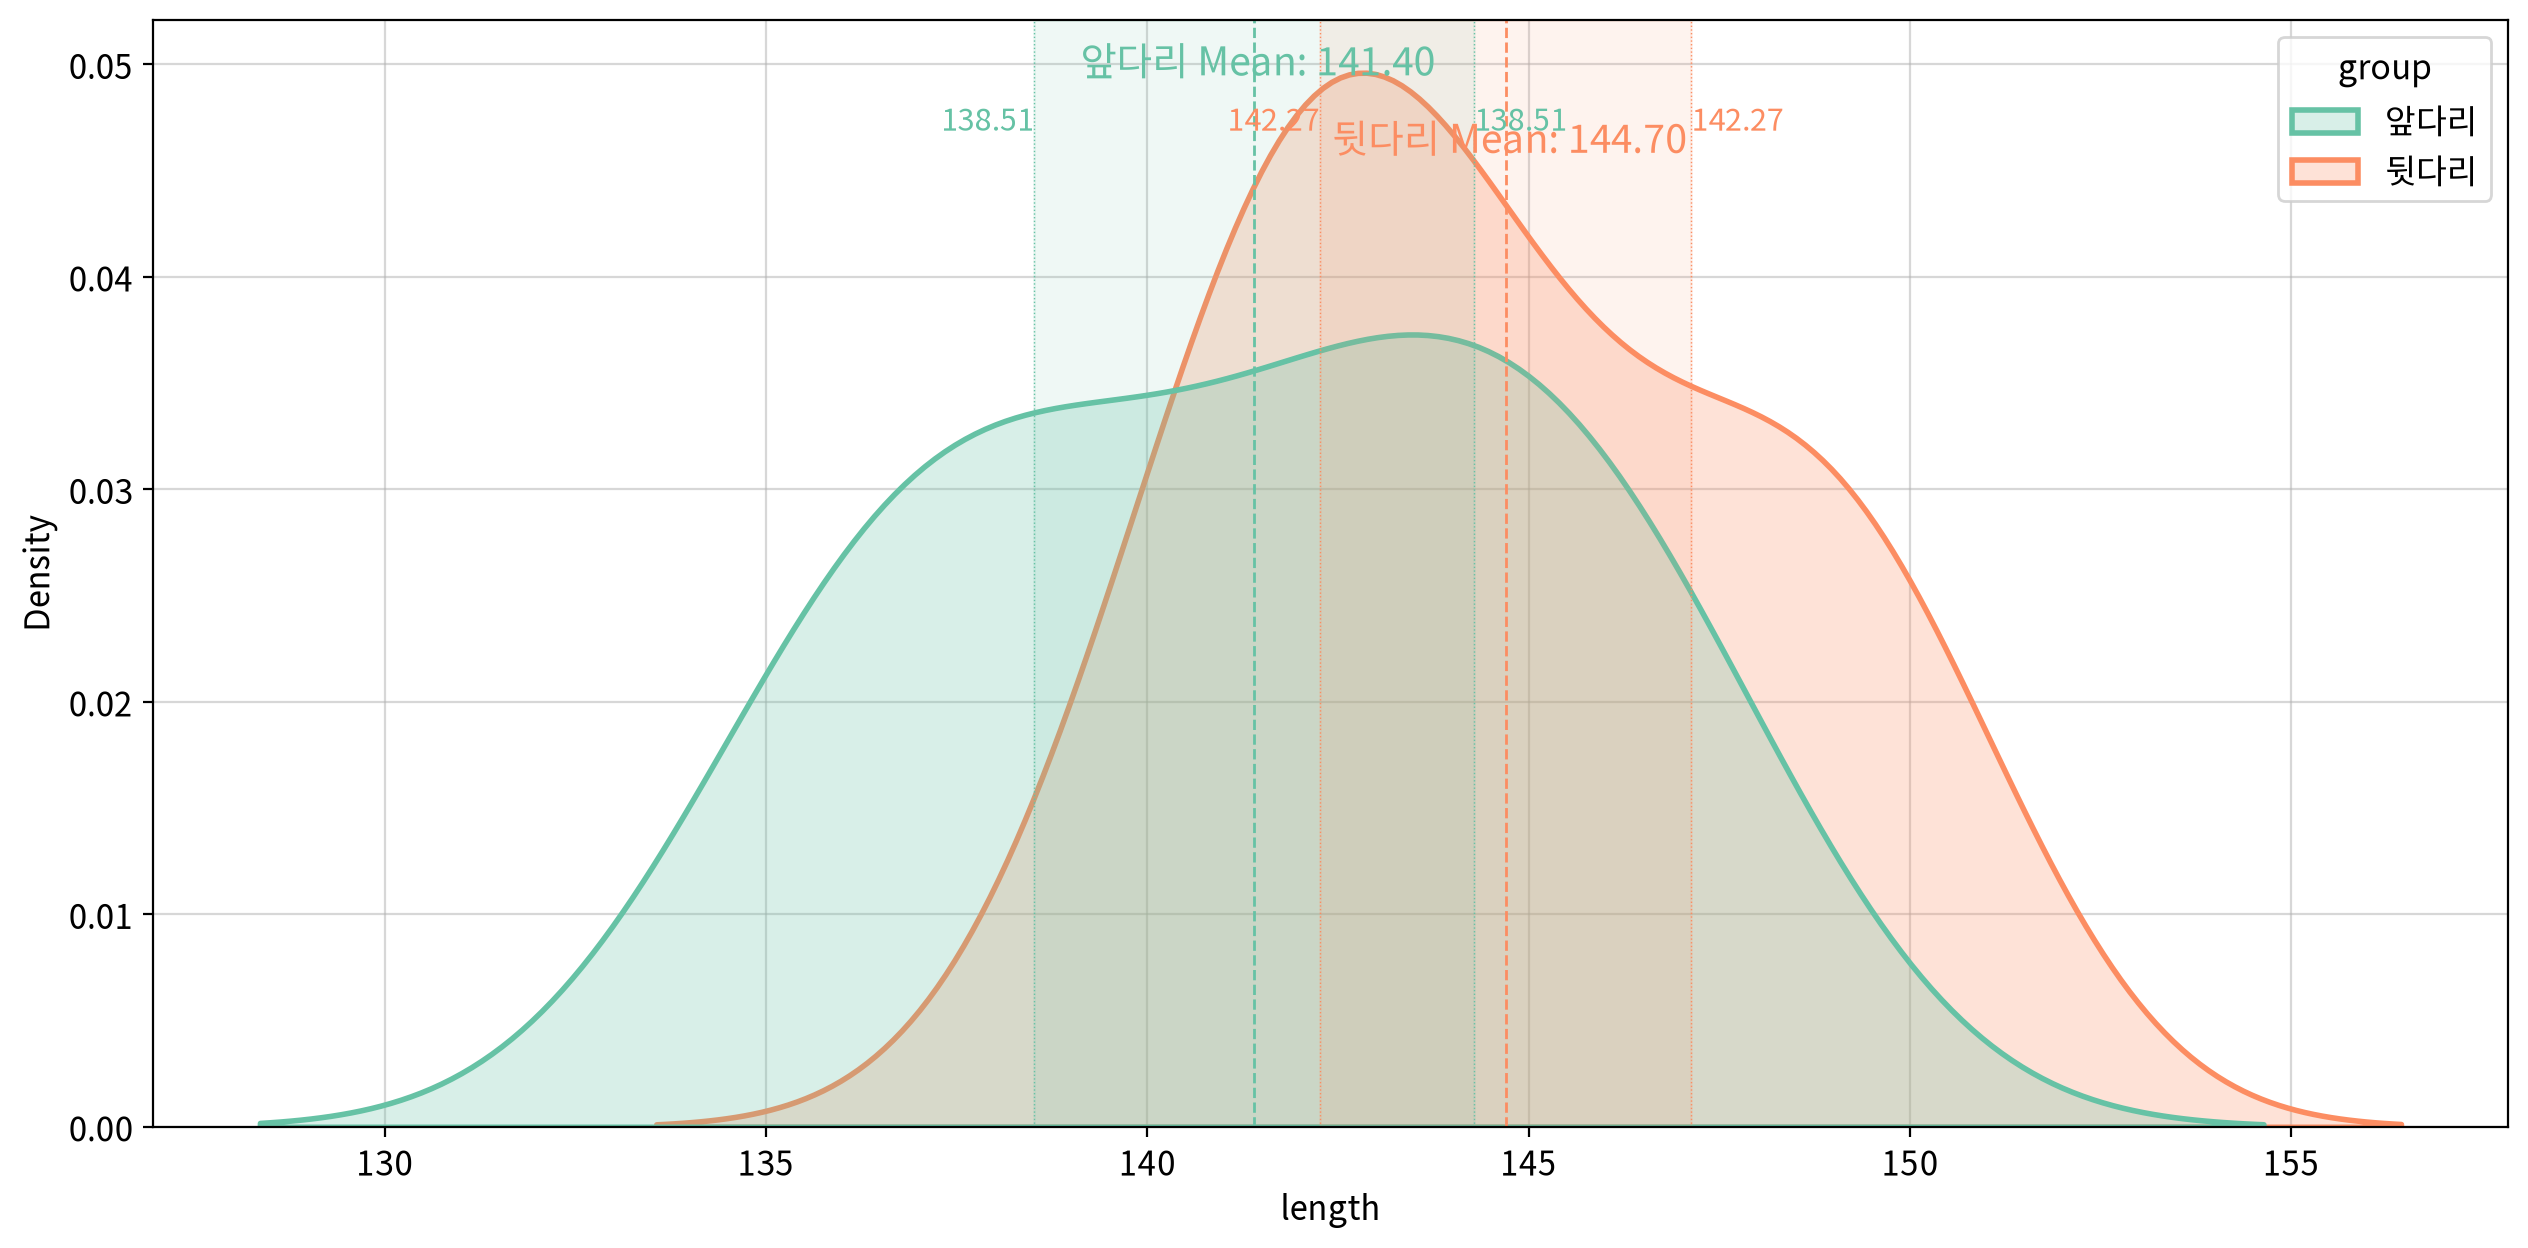

In [6]:
my_plot.kdeplot(data=df1_melt, x='length', hue='group', fill=True, meanline=True, clevel=0.95, palette='Set2')

> 인사이트
> - 두 그룹의 커널 밀도 함수 그래프의 모양이 정규분포를 띄고 있는지 확실하지 않다.
> - 또한 두 그룹의 데이터 분포가 서로 다르기 때문에 등분산성을 충족하지 않지만 대응표본은 정규성만 충족하면 되므로 이는 영향이 없다.

#### 4. 가설검정의 가정을 확인하기 위한 파생변수 생성

- 대응표본은 after에서 before를 뺀 값에 대하여 정규성을 검정해야 한다.

In [7]:
df1_diff = df1.copy()
df1_diff['diff'] = df1_diff['뒷다리'] - df1_diff['앞다리']
df1_diff.head()

,앞다리,뒷다리,diff
사슴,,,
1,138,142,4
2,136,140,4
3,147,144,-3
4,139,144,5
5,143,142,-1


#### 5. 차이값에 대한 정규성 검정

In [8]:
my_stats.test_assumptions(data=df1_diff, columns='diff')

,test,statistic,p-value,result
field,,,,
diff,normaltest,4.356,0.113,True


> 정규성을 충족하므로 Paired T-Test를 수행한다.

#### 6. Paired T-Test - 양측검정

- 사슴의 앞다리와 뒷다리의 길이가 다른지 검정
    - 두 그룹간의 평균을 비교하기 위해서는 alternative 파라미터를 two-sided로 설정한다.
    - 기본값이므로 생략 가능함

    | 구분        | 수식              | 내용                        |
    | --------- | --------------- | ------------------------- |
    | 귀무가설 (H₀) | μ(뒷다리) = μ(앞다리) | 사슴의 뒷다리와 앞다리 길이에는 차이가 없다. |
    | 대립가설 (H₁) | μ(뒷다리) ≠ μ(앞다리) | 사슴의 뒷다리와 앞다리 길이에는 차이가 있다. |

In [9]:
s, p = ttest_rel(df1['뒷다리'], df1['앞다리'], alternative='two-sided')
print(f"t-statistic: {s:.4f}, p-value: {p:.4f}")

t-statistic: 3.4138, p-value: 0.0077


> 차이값에 대한 양측검정 수행 결과 귀무가설을 기각하고 대립가설을 채택한다. (p < 0.05)   
> 즉, 사슴의 앞다리와 뒷다리의 길이는 통계적으로 유의한 차이가 있다.

#### 7. Paired T-Test - 좌측 단측검정

- 사슴의 앞다리가 뒷다리보다 짧은지 검정
    - 두 그룹간의 평균을 비교하기 위해서는 alternative 파라미터를 less로 설정한다.

    | 구분        | 수식              | 내용                        |
    | --------- | --------------- | ------------------------- |
    | 귀무가설 (H₀) | μ(뒷다리) >= μ(앞다리) | 사슴의 뒷다리는 앞다리 길이보다 짧지 않다. |
    | 대립가설 (H₁) | μ(뒷다리) < μ(앞다리) | 사슴의 뒷다리는 앞다리 길이보다 **짧다**. |

In [10]:
s, p = ttest_rel(df1['뒷다리'], df1['앞다리'], alternative='less')
print(f"t-statistic: {s:.4f}, p-value: {p:.4f}")

t-statistic: 3.4138, p-value: 0.9961


> 차이값에 대한 좌측 단측검정 수행 결과 귀무가설을 기각할 수 없다. (p >= 0.05)   
> 즉, 사슴의 뒷다리 길이는 앞다리 길이보다 **통계적으로 유의하게 짧지 않다**.

#### 8. Paired T-Test - 우측 단측검정

- 사슴의 앞다리가 뒷다리보다 긴지 검정
    - 두 그룹간의 평균을 비교하기 위해서는 alternative 파라미터를 greater로 설정한다.

    | 구분        | 수식              | 내용                        |
    | --------- | --------------- | ------------------------- |
    | 귀무가설 (H₀) | μ(뒷다리) <= μ(앞다리) | 사슴의 뒷다리는 앞다리 길이보다 길지 않다. |
    | 대립가설 (H₁) | μ(뒷다리) > μ(앞다리) | 사슴의 뒷다리는 앞다리 길이보다 **길다**. |

In [11]:
s, p = ttest_rel(df1['뒷다리'], df1['앞다리'], alternative='greater')
print(f"t-statistic: {s:.4f}, p-value: {p:.4f}")

t-statistic: 3.4138, p-value: 0.0039


> 차이값에 대한 양측검정 수행 결과 귀무가설을 기각하고 대립가설을 채택한다. (p < 0.05)   
> 즉, 사슴의 뒷다리 길이는 앞다리 길이보다 **통계적으로 유의하게 길다.**

#### 9. 가설검정 시각화

- 상자그림에 Annotator 클래스의 객체를 사용하여 평균 비교를 추가할 수 있다.
    - 양측 검정만 지원하고 단측 검정은 지원하지 않음

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

앞다리 vs. 뒷다리: t-test paired samples, P_val:7.703e-03 t=-3.414e+00


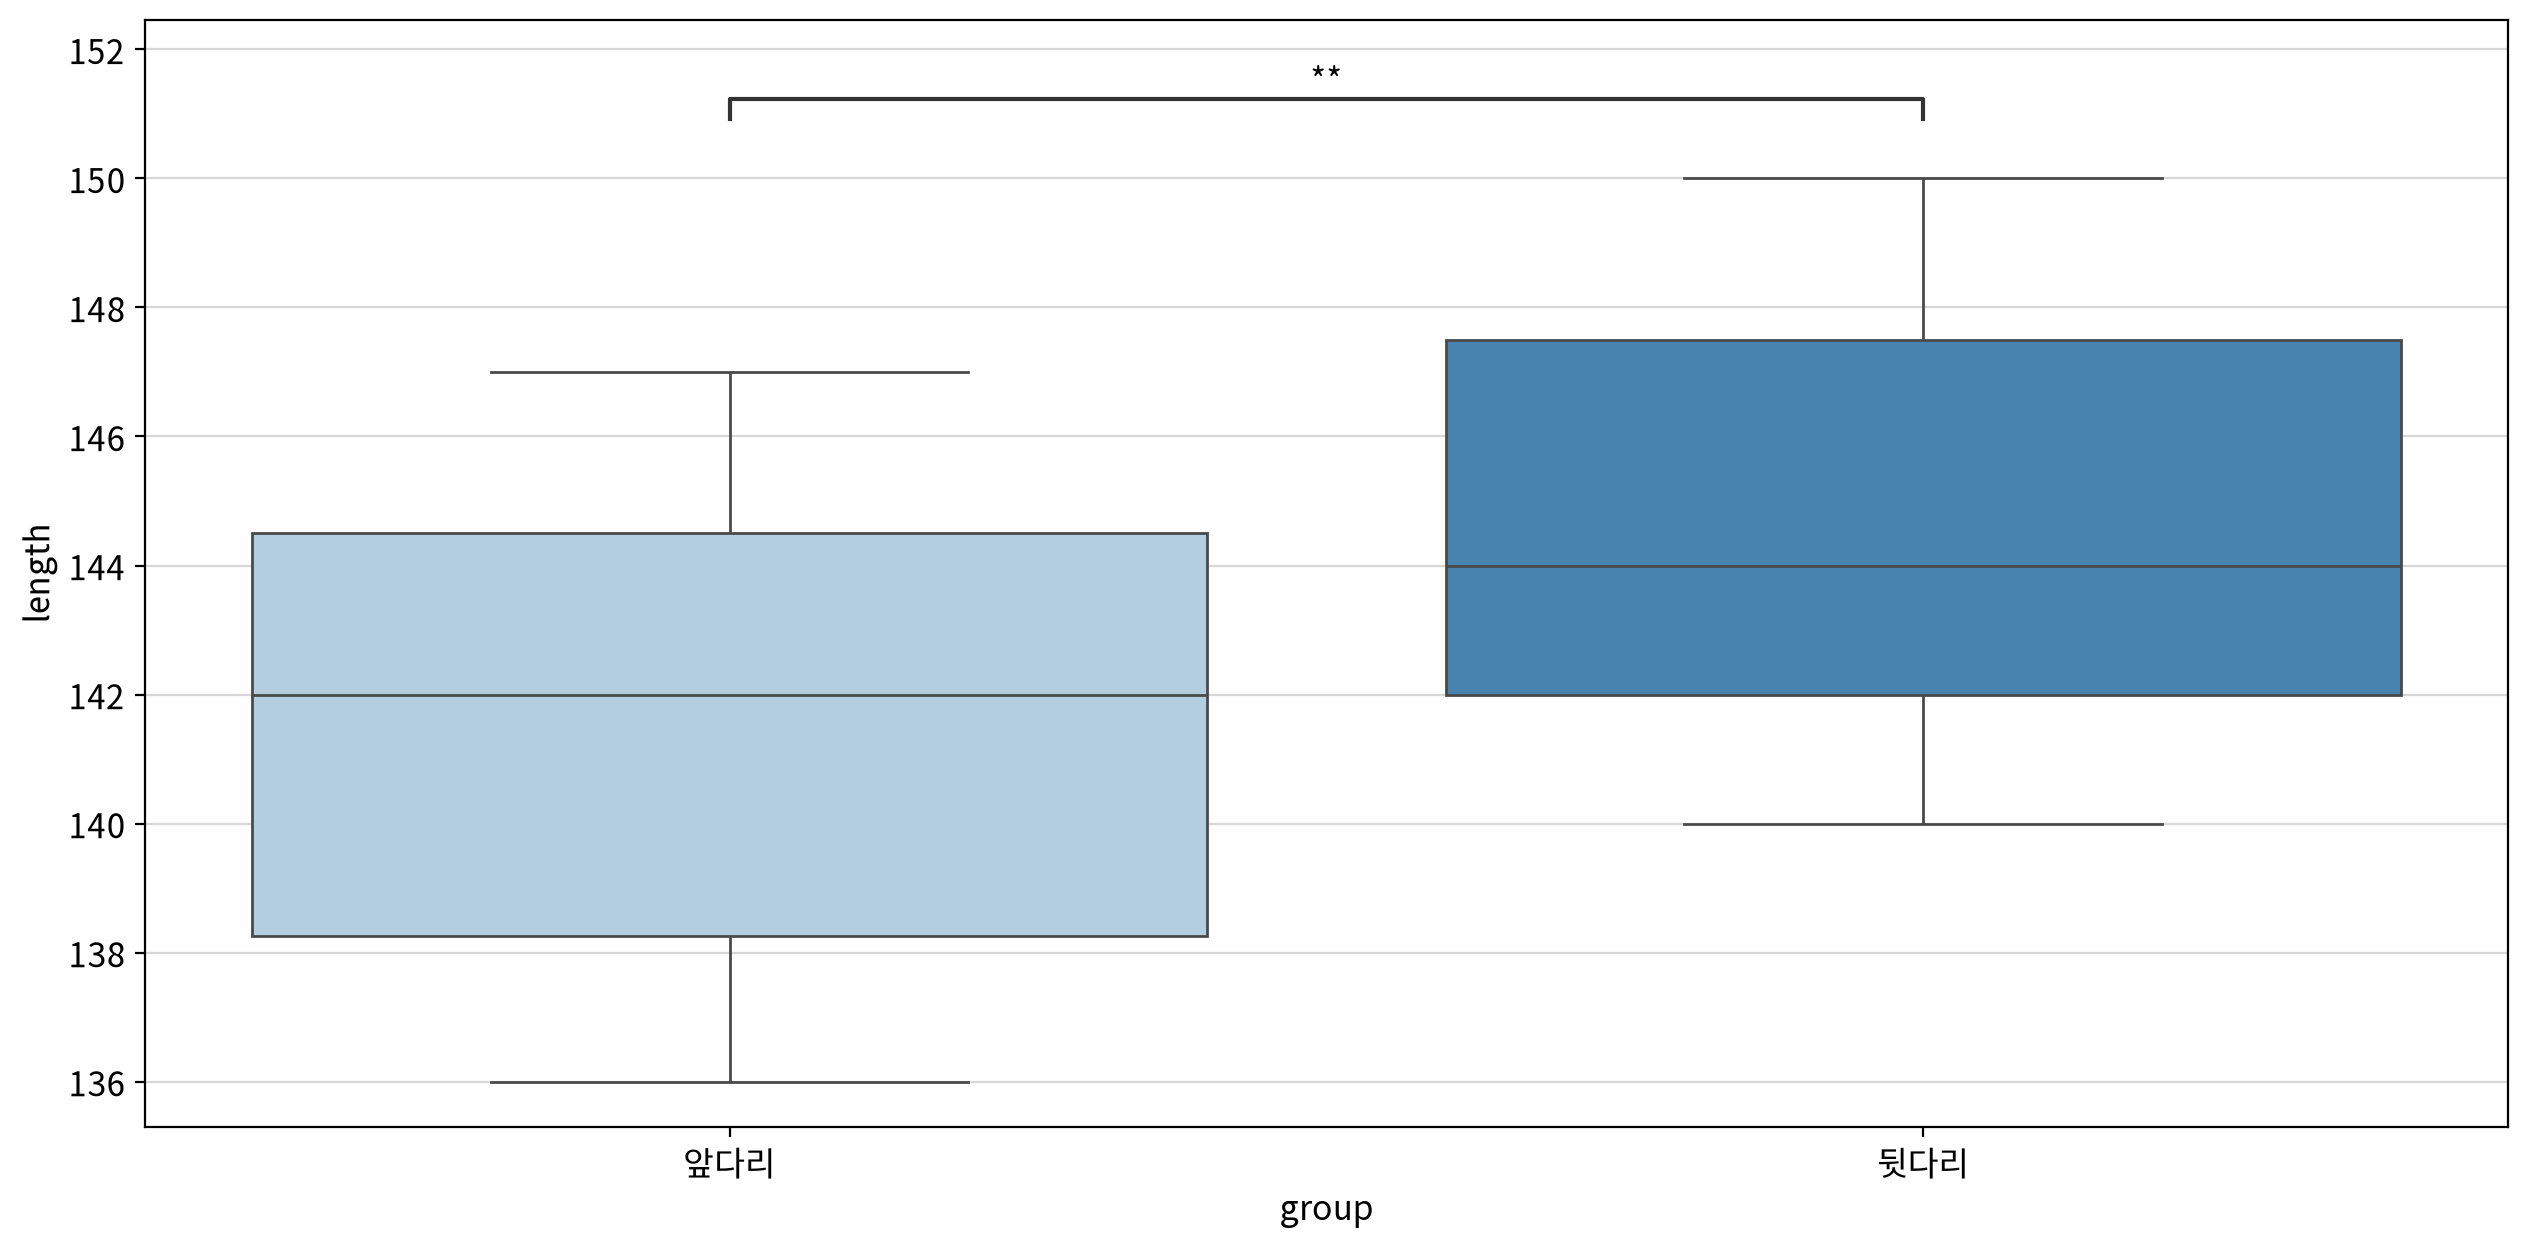

In [12]:
fig, ax = my_plot.init()
my_plot.boxplot(data=df1_melt, x="group", y="length", hue="group", palette="Blues", ax=ax)

# 독립표본 T검정 결과를 시각화에 추가
annotator = Annotator(data=df1_melt,               # 데이터프레임
                       x='group',                   # x축 변수
                       y='length',                  # y축 변수
                       pairs=[('앞다리', '뒷다리')],  # 비교할 그룹 쌍
                       ax=ax)                       # 그래프 축

# 가설검정 알고리즘 종류 (`t-test_ind`, `t-test_paired`, `t-test_welch`, `Mann-Whitney`,
#                     `Mann-Whitney-gt`, `Mann-Whitney-ls`, `Levene`, `Wilcoxon`, `Krustal` 등을 지원)
annotator.configure(test='t-test_paired')
annotator.apply_and_annotate()

my_plot.show()

### #03 예제(2) - 자동차 첨가제가 주행거리에 미치는 영향

#### 1. 데이터 가져오기

- 다섯 종류의 새 차에 대하여 같은 종류의 차 두 대 중에서 한 대를 랜덤으로 선택하여 첨가제를 사용하고, 다른 한 대에는 첨가제를 사용하지 않고 같은 운전자가 같은 장소에서 운정한 결과 다음과 같은 자료를 얻었다.
    - 첨가제를 사용하면 주행거리가 늘어난다고 할 수 있는지 유의수준 5%에서 검정해보라.
    - 그룹A: 첨가제를 사용한 경우
    - 그룹B: 첨가제를 사용하지 않은 경우

In [13]:
df2 = load_data("oil")
df2.head()

📚 다섯 종류의 새 차에 대하여 같은 종류의 차 두 대 중에서 한 대를 랜덤하게 선택하여 첨가제를 사용하고, 다른 한 대에는 첨가제를 사용하지 않고 같은 운전자가 같은 장소에서 운전한 후 주행거리를 측정한 결과 데이터 (출처: 방송통신대학교 통계학개론)


,그룹A,그룹B
0,13.200,11.700
1,13.100,17.984
2,16.300,12.290
3,14.900,9.862
4,14.200,8.871


> 같은 종류의 차 2대가 한 쌍으로 묶여있고 한 대는 첨가제 사용, 다른 한 대는 미사용이므로 대응표본 비교임

#### 2. 시각화를 위한 데이터 재배치

- melt 함수를 사용하여 wide형 데이터를 long형으로 변환한다.

In [14]:
df2_melt = melt(df2, var_name="group", value_name="length")
df2_melt.head()

,group,length
0,그룹A,13.200
1,그룹A,13.100
2,그룹A,16.300
3,그룹A,14.900
4,그룹A,14.200


#### 3. 데이터 분포 시각화

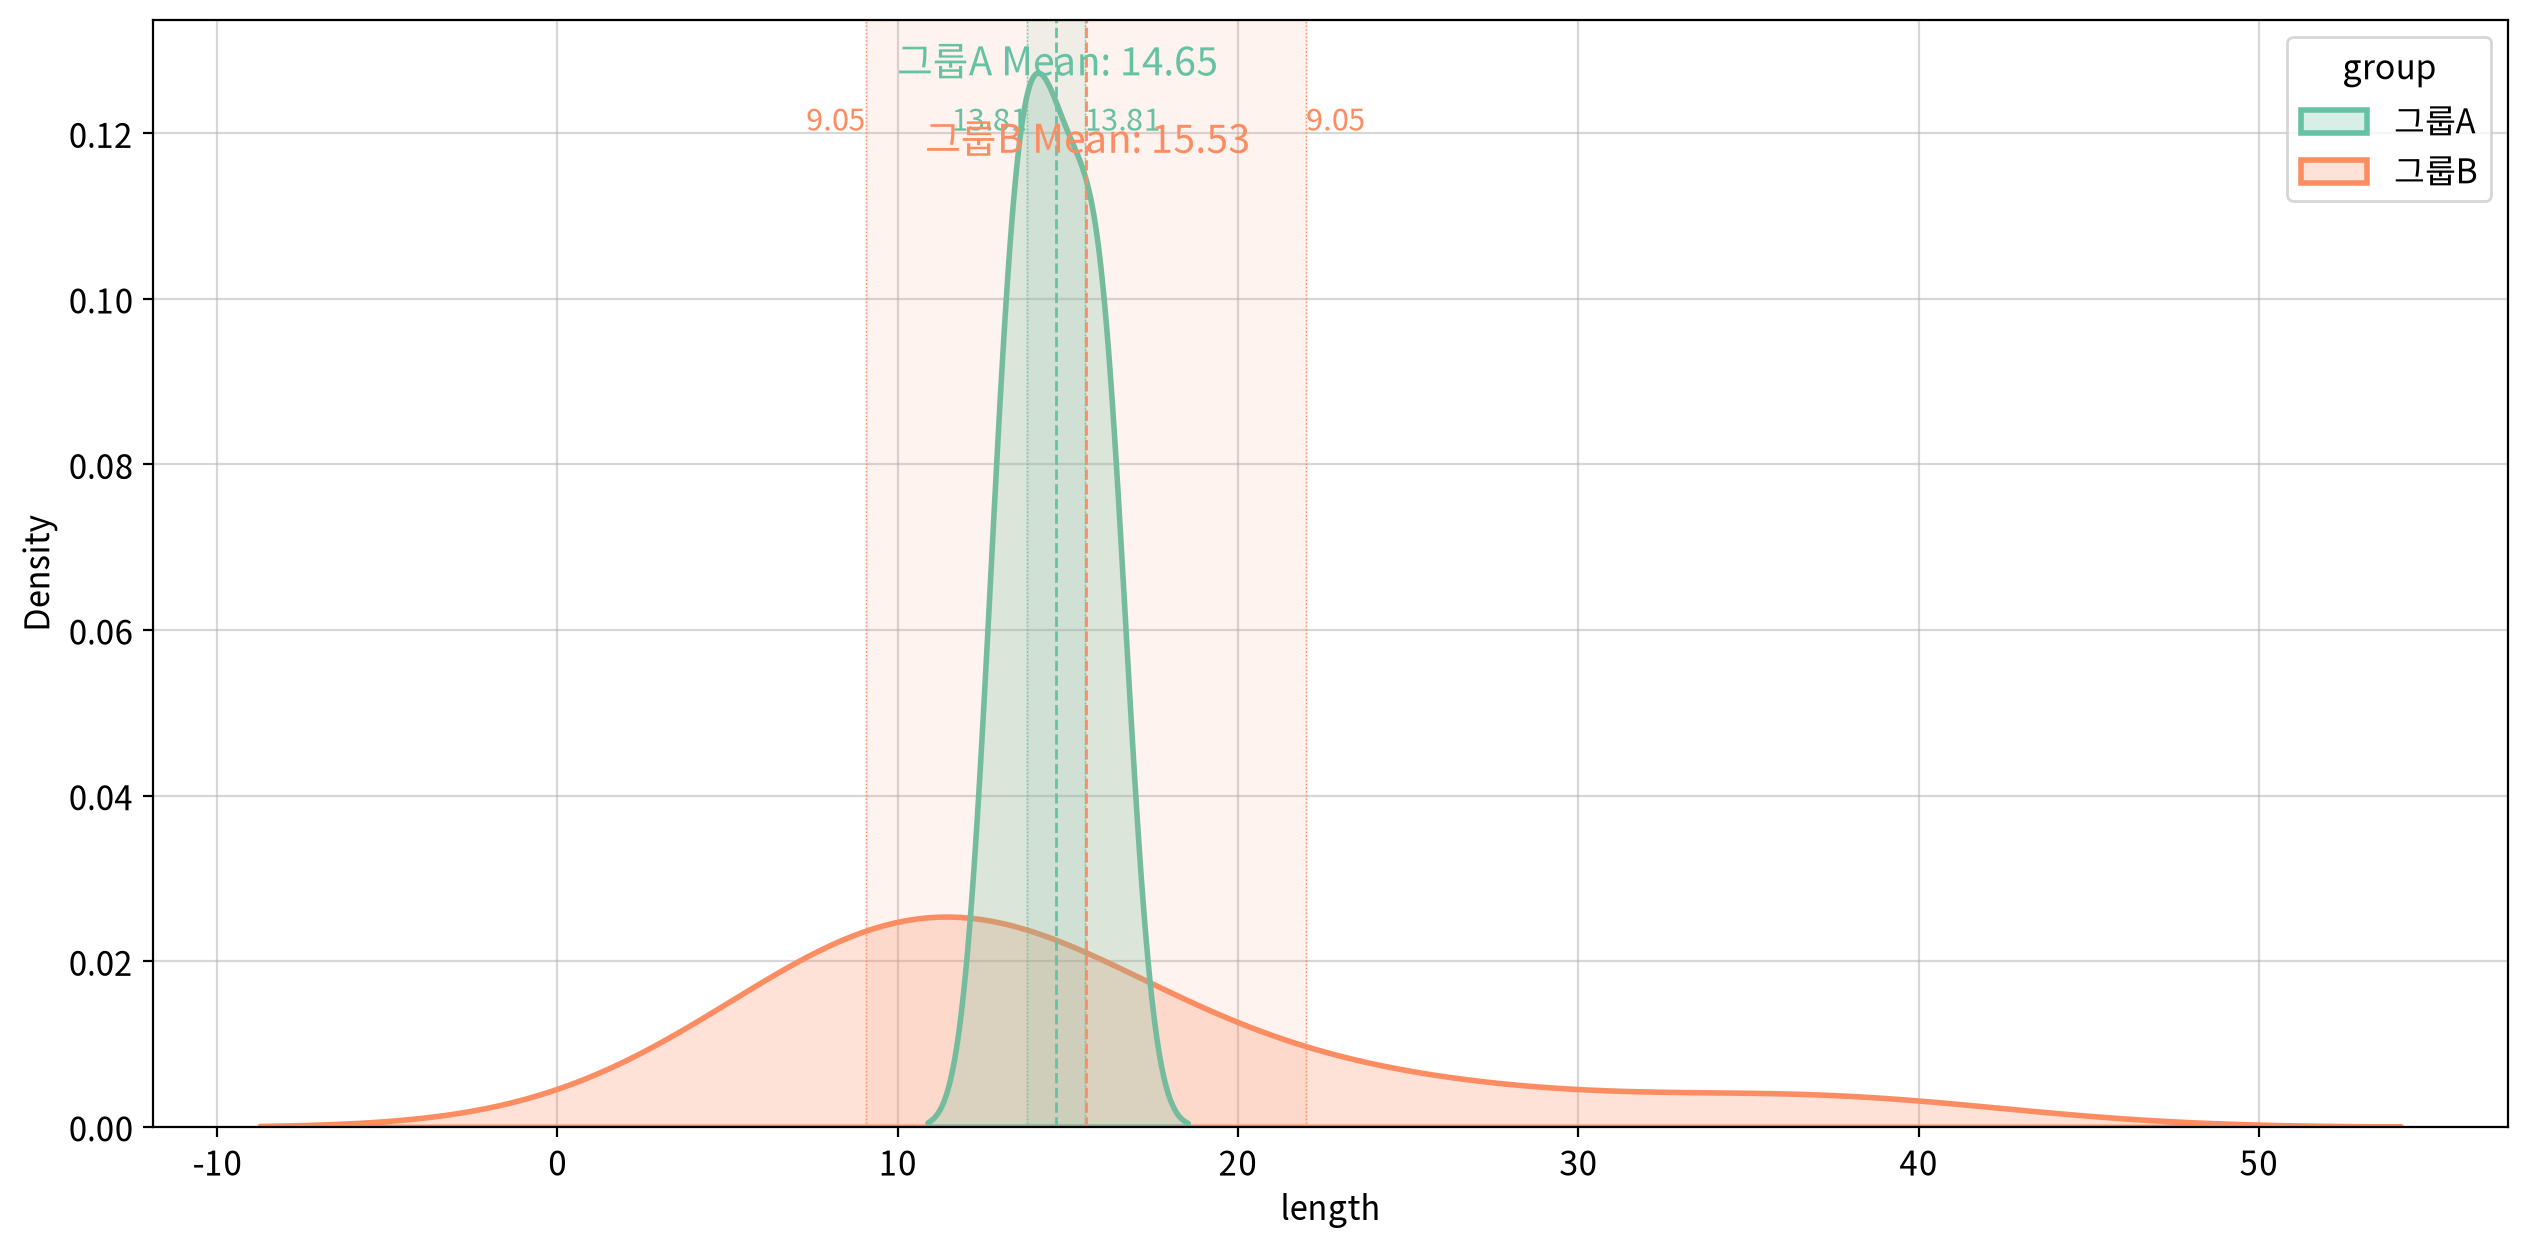

In [15]:
my_plot.kdeplot(data=df2_melt, x='length', hue='group', fill=True, meanline=True, clevel=0.95, palette='Set2')

> 인사이트
> - 그룹 A는 정규분포 모양을 띄지만 그룹 B는 약한 우측 꼬리 형태를 띄고 있어 정규성 가정을 충족하지 않는다.
> - 또한 두 그룹의 분산(데이터의 퍼짐 정도)가 극명하게 다르다.

#### 4. 가설검정 가정 확인

In [16]:
# 차이값 계산
df2_diff = df2.copy()
df2_diff['diff'] = df2_diff['그룹A'] - df2_diff['그룹B']

# 차이에 대한 정규성 검정
my_stats.test_assumptions(data=df2_diff, columns='diff')

,test,statistic,p-value,result
field,,,,
diff,normaltest,7.990,0.018,False


> 데이터가 정규성을 만족하지 않는다. (대응표본 T검정은 등분산성을 확인하지 않는다.)
> 정규성을 충족하지 않기 때문에 Wilcoxon signed-rank test를 수행해야 한다.

#### 5. Wilcoxon signed-rank test - 양측검정

| 구분        | 수식          | 내용                                                                               |
| --------- | ----------- | -------------------------------------------------------------------------------- |
| 귀무가설 (H₀) | μ(A) = μ(B) | 그룹 A와 그룹 B의 주행거리에는 차이가 없다. <br>즉, 실험에 사용된 첨가제는 주행거리에 영향을 주지 않는다.                     |
| 대립가설 (H₁) | μ(A) ≠ μ(B) | 그룹 A와 그룹 B의 주행거리에는 차이가 있다. <br>즉, 실험에 사용된 첨가제는 주행거리에 영향을 준다. (긍정적, 부정적 영향인지는 알 수 없음) |

In [17]:
s, p = wilcoxon(df2['그룹A'], df2['그룹B'], alternative='two-sided')
print(f"Wilcoxon statistic: {s:.4f}, p-value: {p:.4f}")

Wilcoxon statistic: 24.0000, p-value: 0.7695


> 첨가제를 사용한 그룹과 첨가제를 사용하지 않은 그룹의 평균 주행거리에 대해 양측검정을 수행한 결과   
> 통계적으로 유의미한 차이를 보이지 않았다. (p >= 0.05)

#### 6. Wilcoxon signed-rank test - 좌측 단측검정

| 구분        | 수식          | 내용                                                                                             |
| --------- | ----------- | ---------------------------------------------------------------------------------------------- |
| 귀무가설 (H₀) | μ(A) ≥ μ(B) | 첨가제를 사용한 그룹 A의 주행거리는 첨가제를 사용하지 않은 그룹 B의 주행거리보다 작지 않다.<br>즉, 실험에 사용된 첨가제는 주행거리에 나쁜 영향을 주지는 않는다.    |
| 대립가설 (H₁) | μ(A) < μ(B) | 첨가제를 사용한 그룹 A의 주행거리는 첨가제를 사용하지 않은 그룹 B의 주행거리보다 작다.<br>즉, 실험에 사용된 첨가제는 주행거리에 안 좋은 영향을 준다. (부정적 영향) |

In [18]:
s, p = wilcoxon(df2['그룹A'], df2['그룹B'], alternative='less')
print(f"Wilcoxon statistic: {s:.4f}, p-value: {p:.4f}")

Wilcoxon statistic: 31.0000, p-value: 0.6523


> 첨가제를 사용한 A그룹과 첨가제를 사용하지 않은 B그룹의 평균 주행거리에 대해 좌측 단측검정을 수행한 결과   
> 통계적으로 유의미한 차이를 보이지 않았다. (p >= 0.05)
> - 주행거리를 늘리도록 작용하거나 주행거리에 영향이 없다는 의미이다.
> - 좌측 단측 검정에서 귀무가설이 채택된 경우 부정적 영향이 없다는 것만 증명될 뿐, 긍정적 영향을 주는지는 알 수 없다.

#### 7. Wilcoxon signed-rank test - 우측 단측검정

| 구분        | 수식          | 내용                                                                                           |
| --------- | ----------- | -------------------------------------------------------------------------------------------- |
| 귀무가설 (H₀) | μ(A) ≤ μ(B) | 첨가제를 사용한 그룹 A의 주행거리는 첨가제를 사용하지 않은 그룹 B의 주행거리보다 크지 않다.<br>즉, 실험에 사용된 첨가제는 주행거리에 긍정적 영향을 주지는 않는다. |
| 대립가설 (H₁) | μ(A) > μ(B) | 첨가제를 사용한 그룹 A의 주행거리는 첨가제를 사용하지 않은 그룹 B의 주행거리보다 크다.<br>즉, 실험에 사용된 첨가제는 주행거리에 좋은 영향을 준다. (긍정적 영향) |

In [19]:
s, p = wilcoxon(df2['그룹A'], df2['그룹B'], alternative='greater')
print(f"Wilcoxon statistic: {s:.4f}, p-value: {p:.4f}")

Wilcoxon statistic: 31.0000, p-value: 0.3848


> 첨가제를 사용한 A그룹과 첨가제를 사용하지 않은 B그룹의 평균 주행거리에 대해 좌측 단측검정을 수행한 결과   
> 통계적으로 유의미한 차이를 보이지 않았다. (p >= 0.05)
> - 주행거리를 늘리도록 작용하거나 주행거리에 영향이 없다는 의미이다.
> - 좌측 단측 검정에서 귀무가설이 채택된 경우 긍정적 영향이 없다는 것만 증명될 뿐, 부정적 영향을 주는지는 알 수 없다.

#### 8. 가설검정 시각화

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

그룹A vs. 그룹B: Wilcoxon test (paired samples), P_val:7.695e-01 Stat=2.400e+01


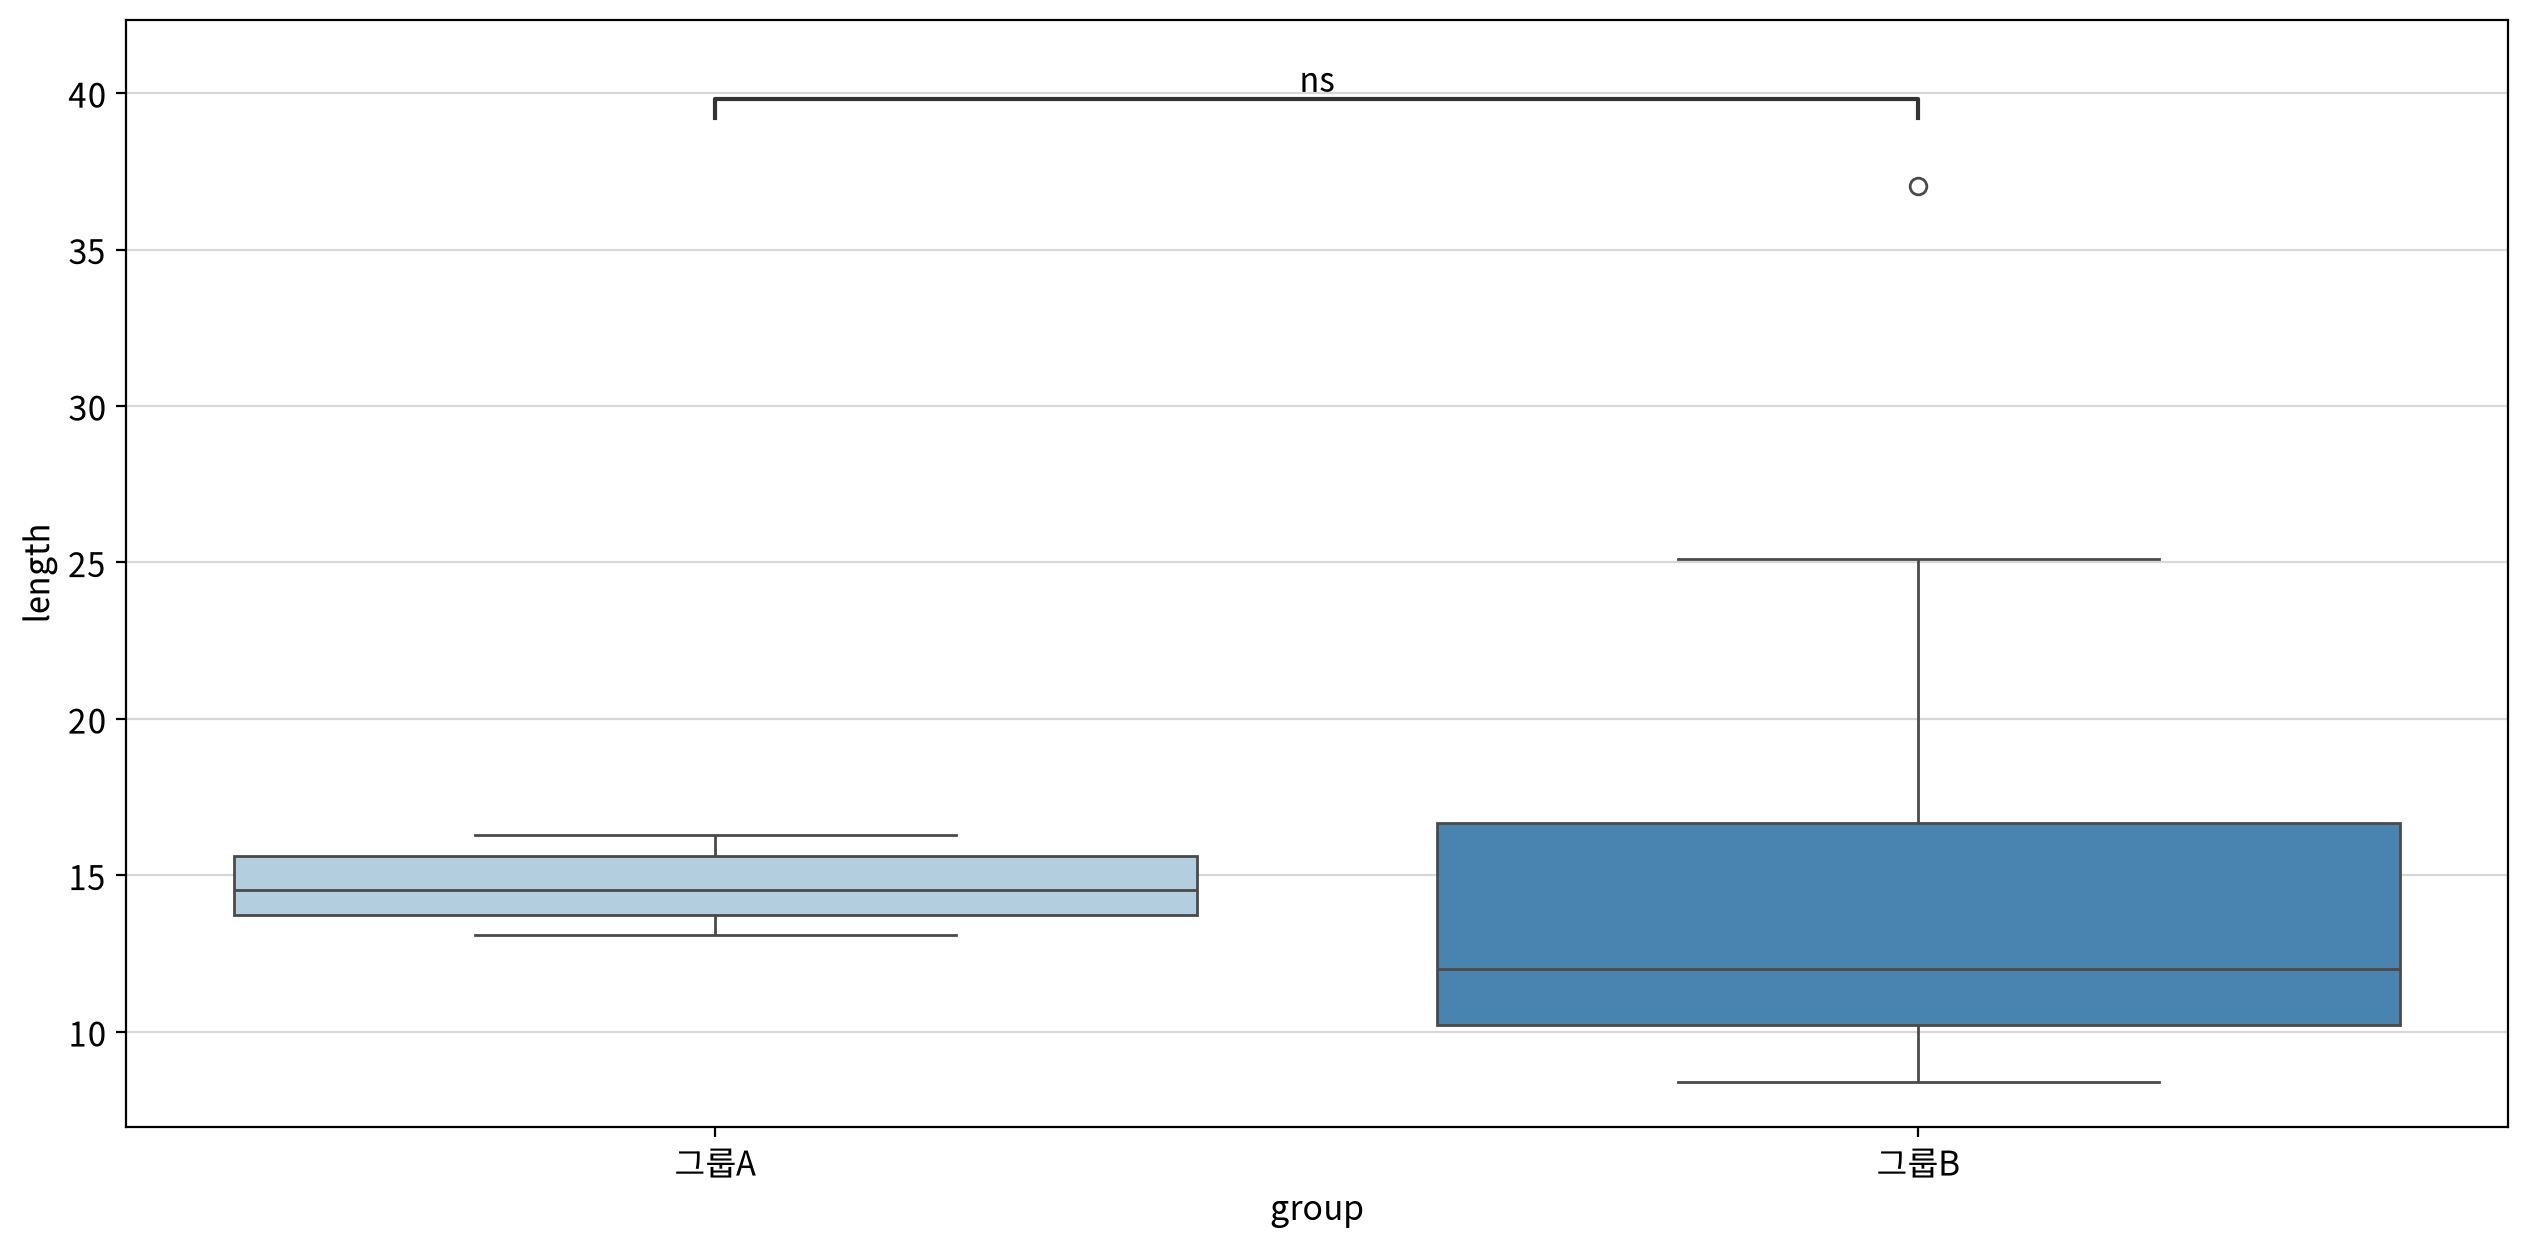

In [20]:
fig, ax = my_plot.init()
my_plot.boxplot(data=df2_melt, x="group", y="length", hue="group", palette="Blues", ax=ax)

# 독립표본 T검정 결과를 시각화에 추가
annotator = Annotator(data=df2_melt,               # 데이터프레임
                       x='group',                   # x축 변수
                       y='length',                  # y축 변수
                       pairs=[('그룹A', '그룹B')],  # 비교할 그룹 쌍
                       ax=ax)                       # 그래프 축

# 가설검정 알고리즘 종류 (`t-test_ind`, `t-test_paired`, `t-test_welch`, `Mann-Whitney`,
#                     `Mann-Whitney-gt`, `Mann-Whitney-ls`, `Levene`, `Wilcoxon`, `Krustal` 등을 지원)
annotator.configure(test='Wilcoxon')
annotator.apply_and_annotate()

my_plot.show()

### #04 모듈화 기능 확인

#### 1. 사슴 다리 길이 비교

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

앞다리 vs. 뒷다리: t-test paired samples, P_val:7.703e-03 t=-3.414e+00


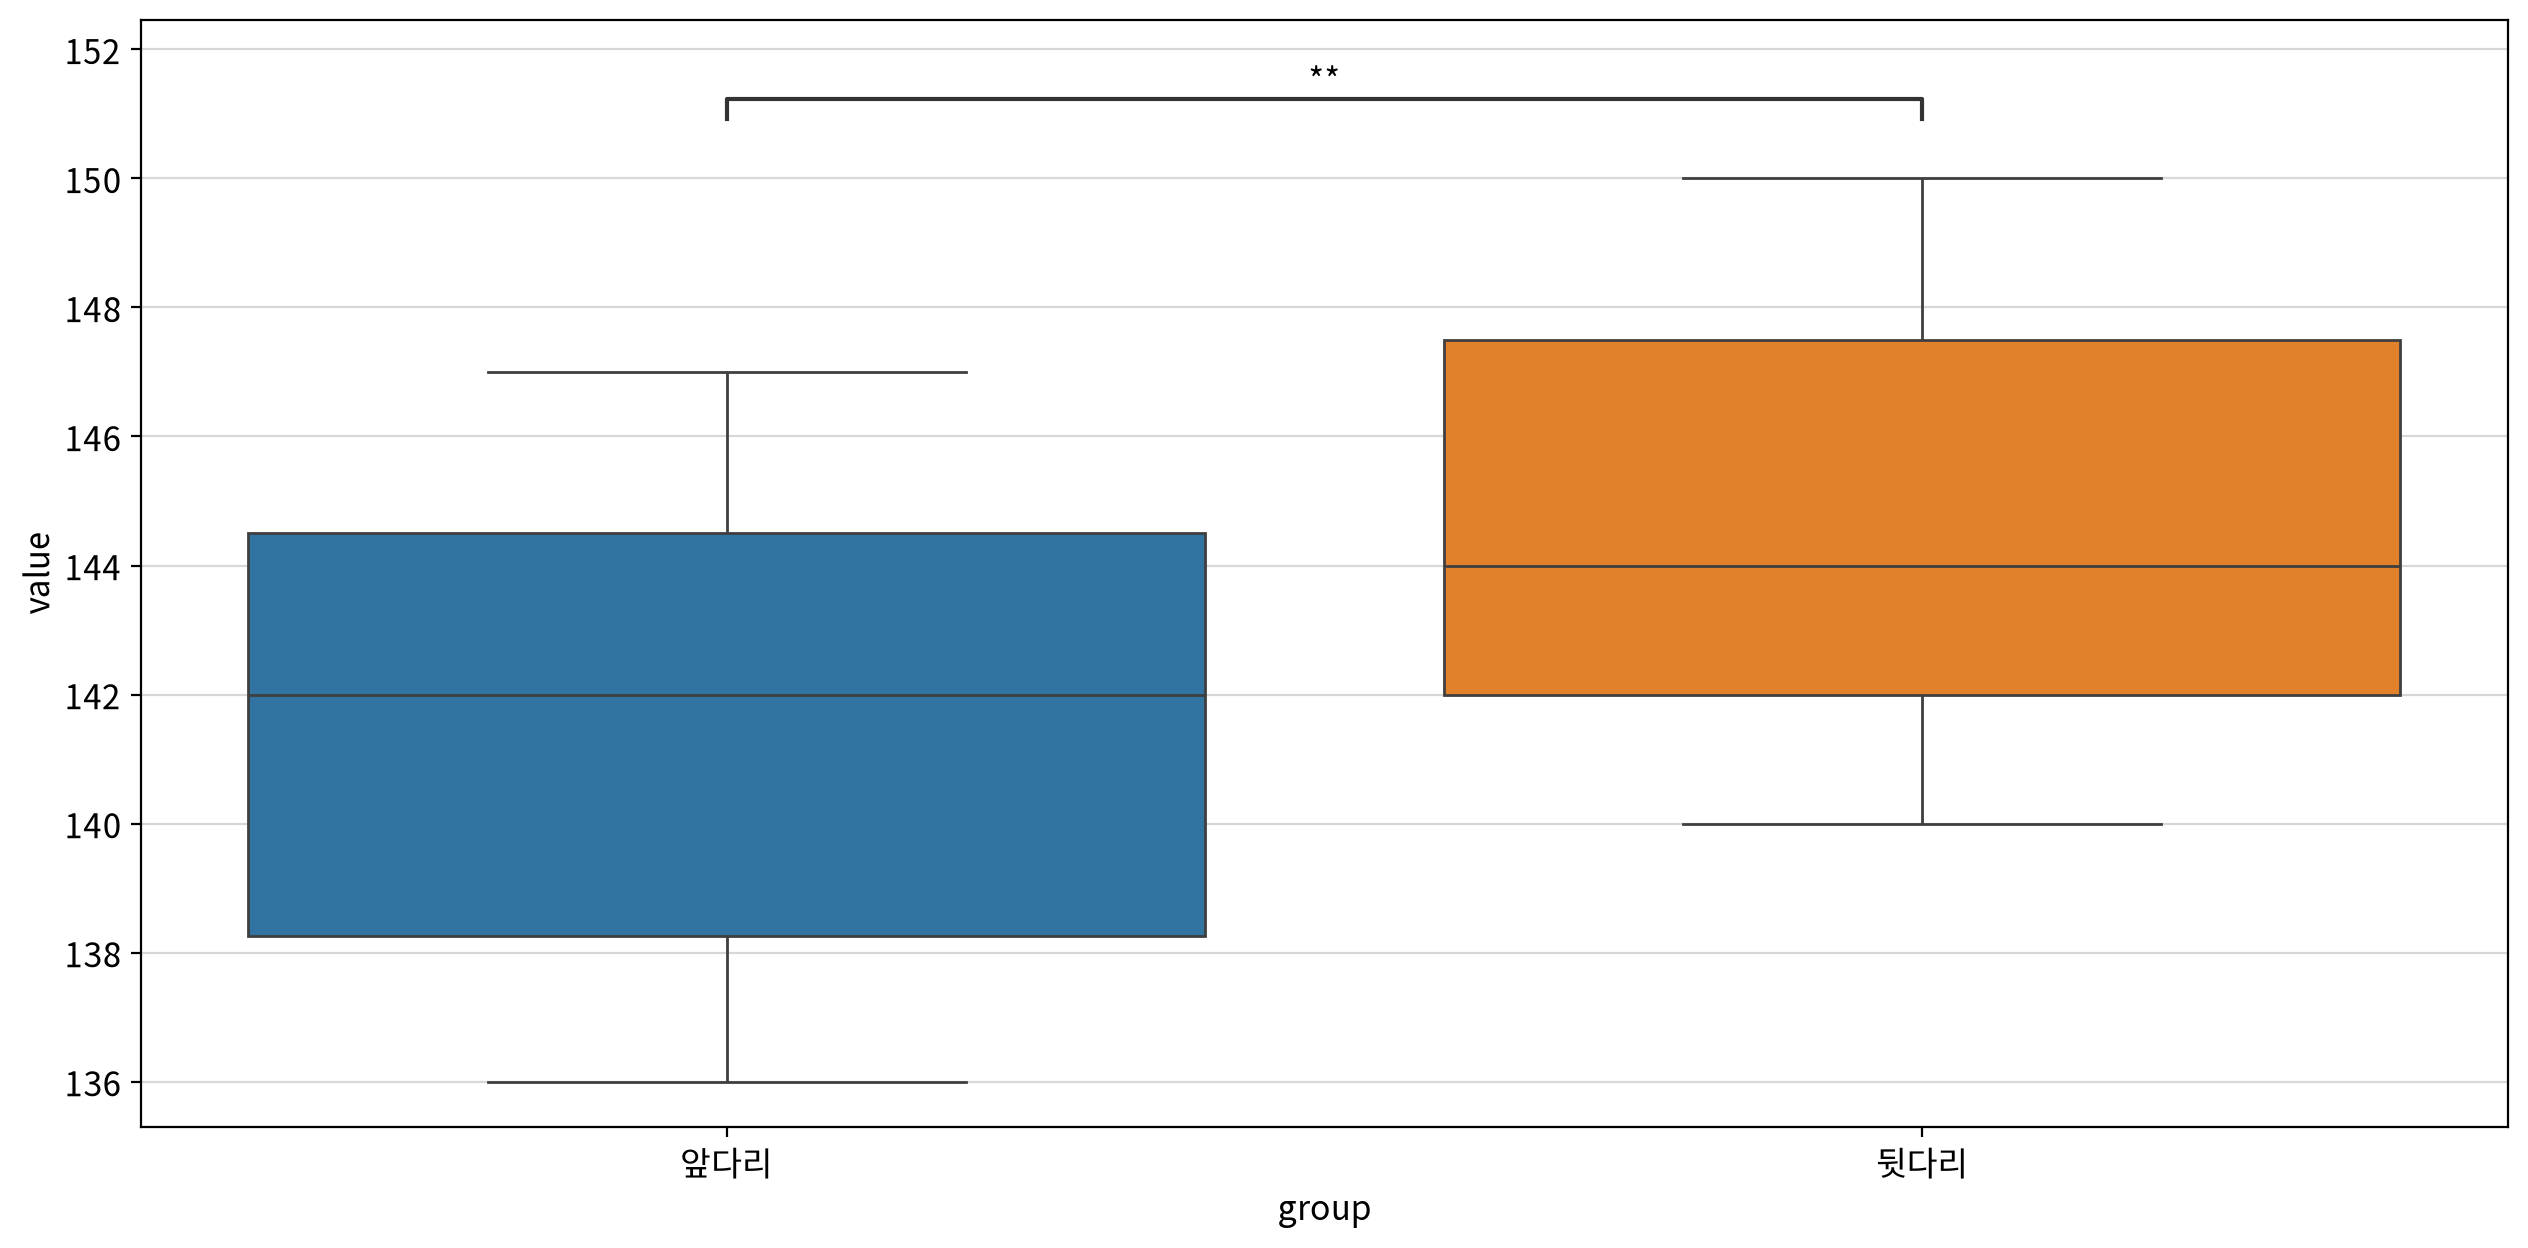

statistic  p-value  significant     result
test          alternative                                            
Paired t-test two-sided        3.414    0.008         True  뒷다리 ≠ 앞다리
              less             3.414    0.996        False  뒷다리 ≥ 앞다리
              greater          3.414    0.004         True  뒷다리 > 앞다리

In [21]:
my_stats.test_paired(data=df1, before='앞다리', after='뒷다리')

#### 2. 자동차 첨가제가 주행거리에 미치는 영향

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

그룹B vs. 그룹A: Wilcoxon test (paired samples), P_val:7.695e-01 Stat=2.400e+01


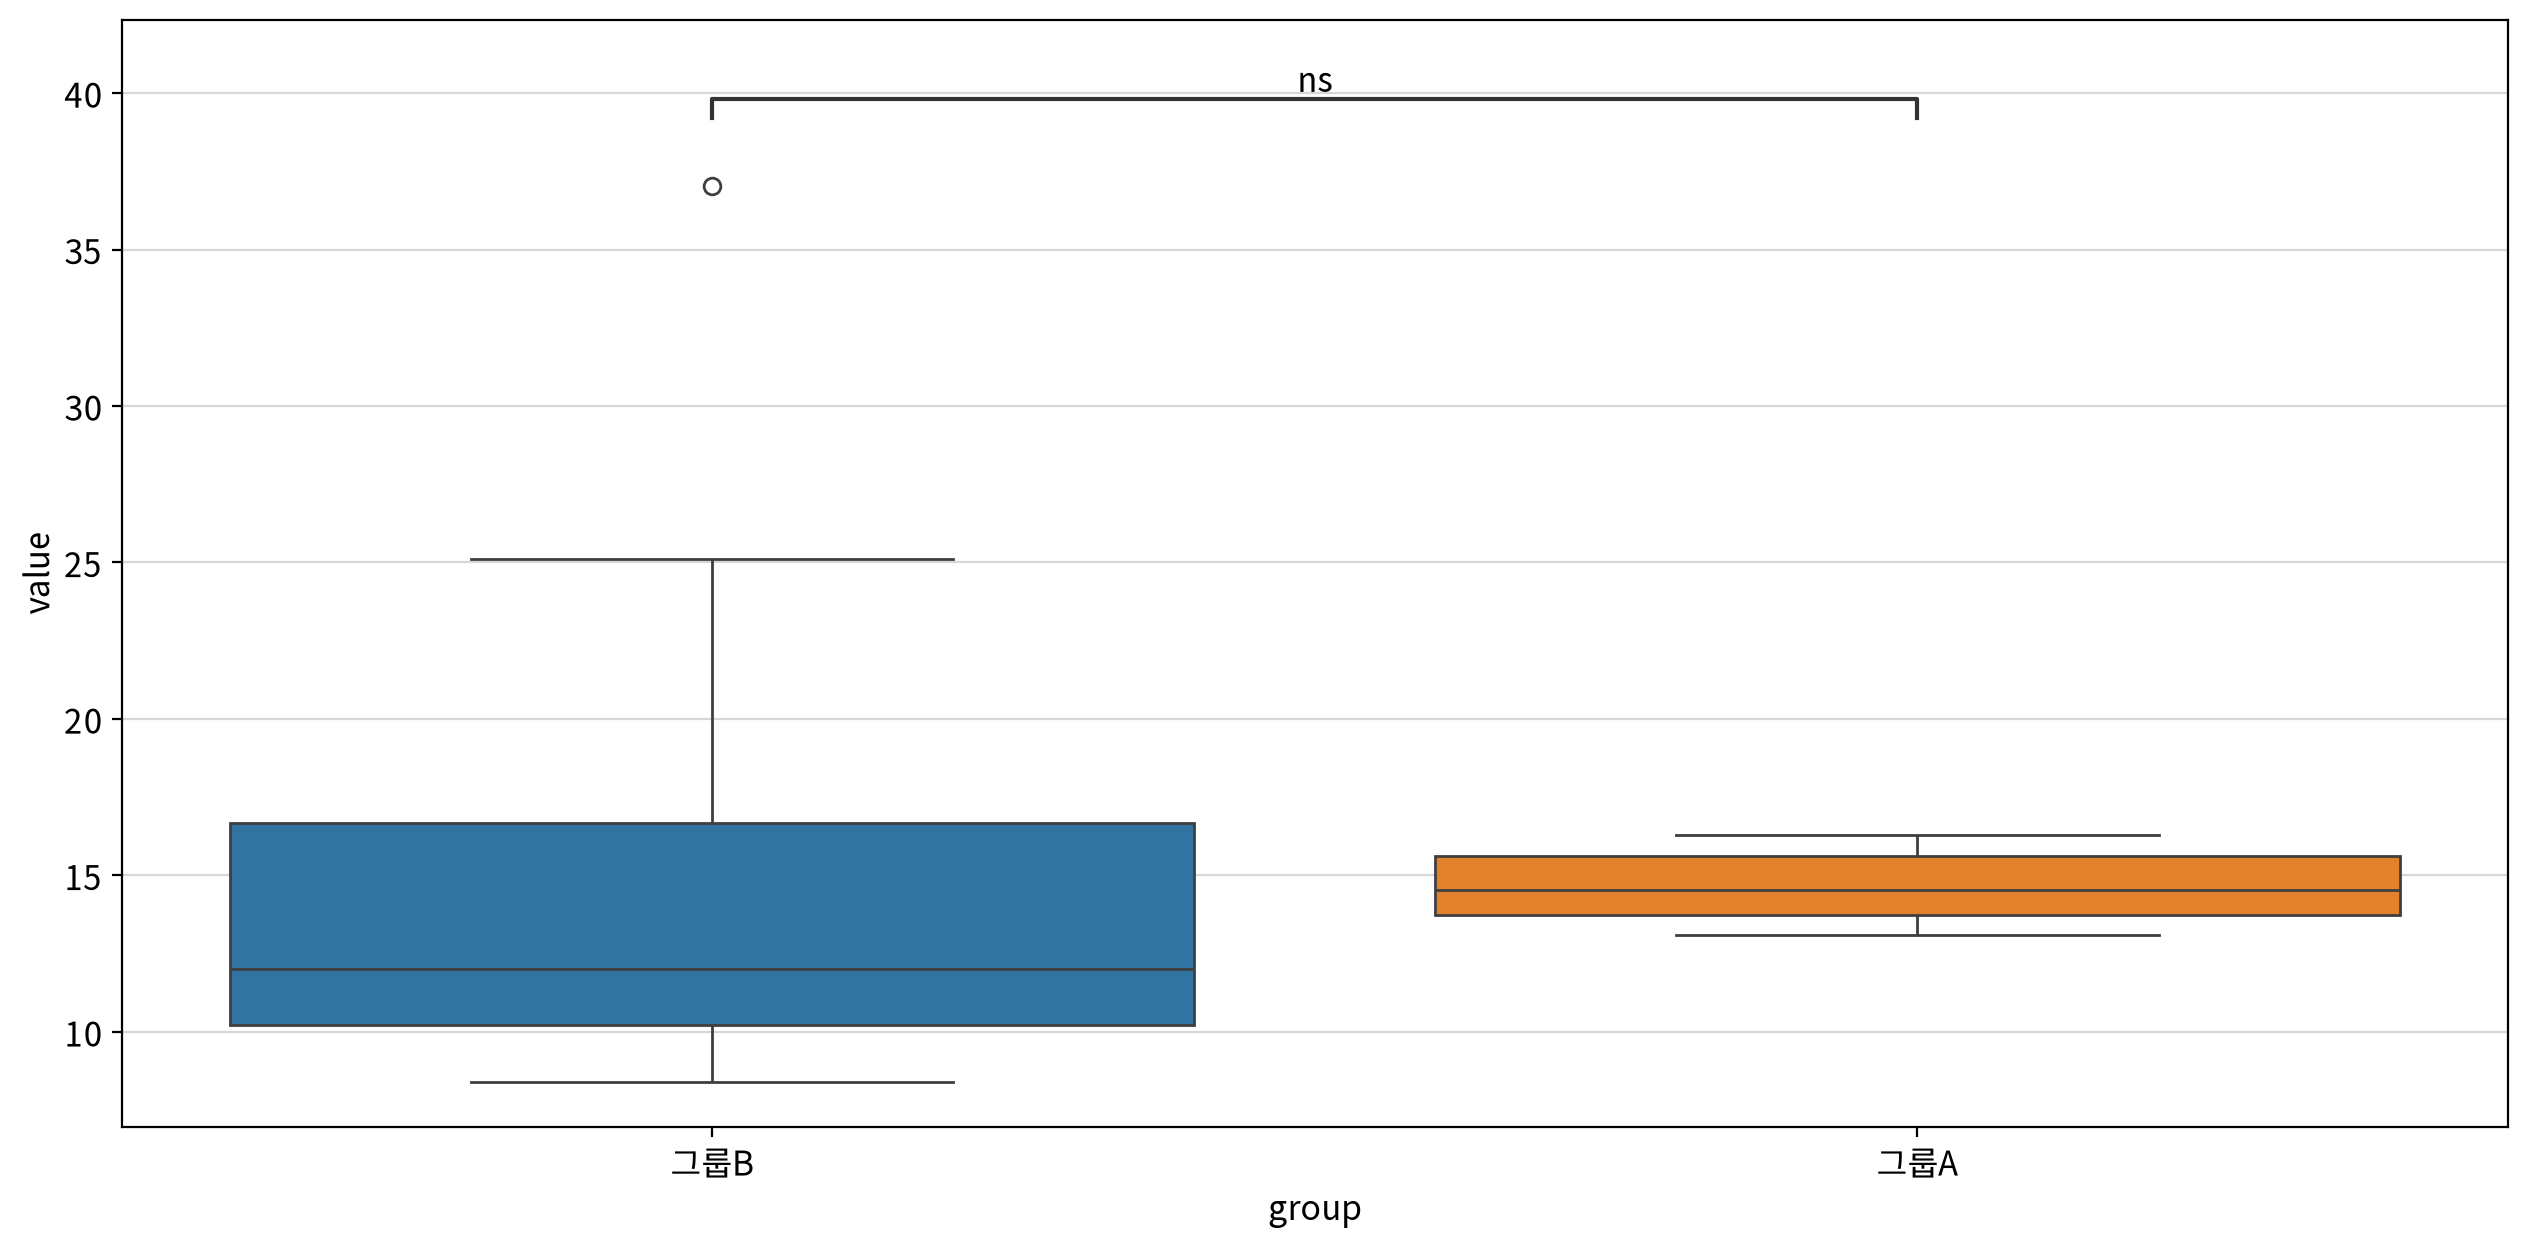

statistic  p-value  significant  \
test                      alternative                                    
Wilcoxon signed-rank test two-sided       24.000    0.769        False   
                          less            31.000    0.652        False   
                          greater         31.000    0.385        False   

                                          result  
test                      alternative             
Wilcoxon signed-rank test two-sided    그룹A = 그룹B  
                          less         그룹A ≥ 그룹B  
                          greater      그룹A ≤ 그룹B

In [22]:
my_stats.test_paired(data=df2, before='그룹B', after='그룹A')

---

## 연습문제

#### 문제1

`blood_pressure` 데이터셋은 부인 15명을 대상으로 평상시 혈압을 측정한 뒤,   
이들에게 이 피임약을 일정 기간 복용하게 한 후 이들의 혈압을 다시 측정한 결과를 기록한 데이터이다.   
이 데이터를 통해 피임약 복용이 혈압에 영향을 주는지 분석하라.   

In [23]:
# 데이터 불러오기
df1 = load_data("blood_pressure")
df1.head()

📚 부인 15명을 대상으로 평상시 혈압을 측정한 뒤, 이들에게 이 피임약을 일정 기간 복용하게 한 후 이들의 혈압을 다시 측정한 결과를 기록한 데이터 (출처: 방송통신대학교 통계학개론)


,복용전,복용후
0,70,68
1,80,72
2,72,62
3,76,70
4,76,58


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

복용전 vs. 복용후: t-test paired samples, P_val:7.749e-03 t=3.105e+00


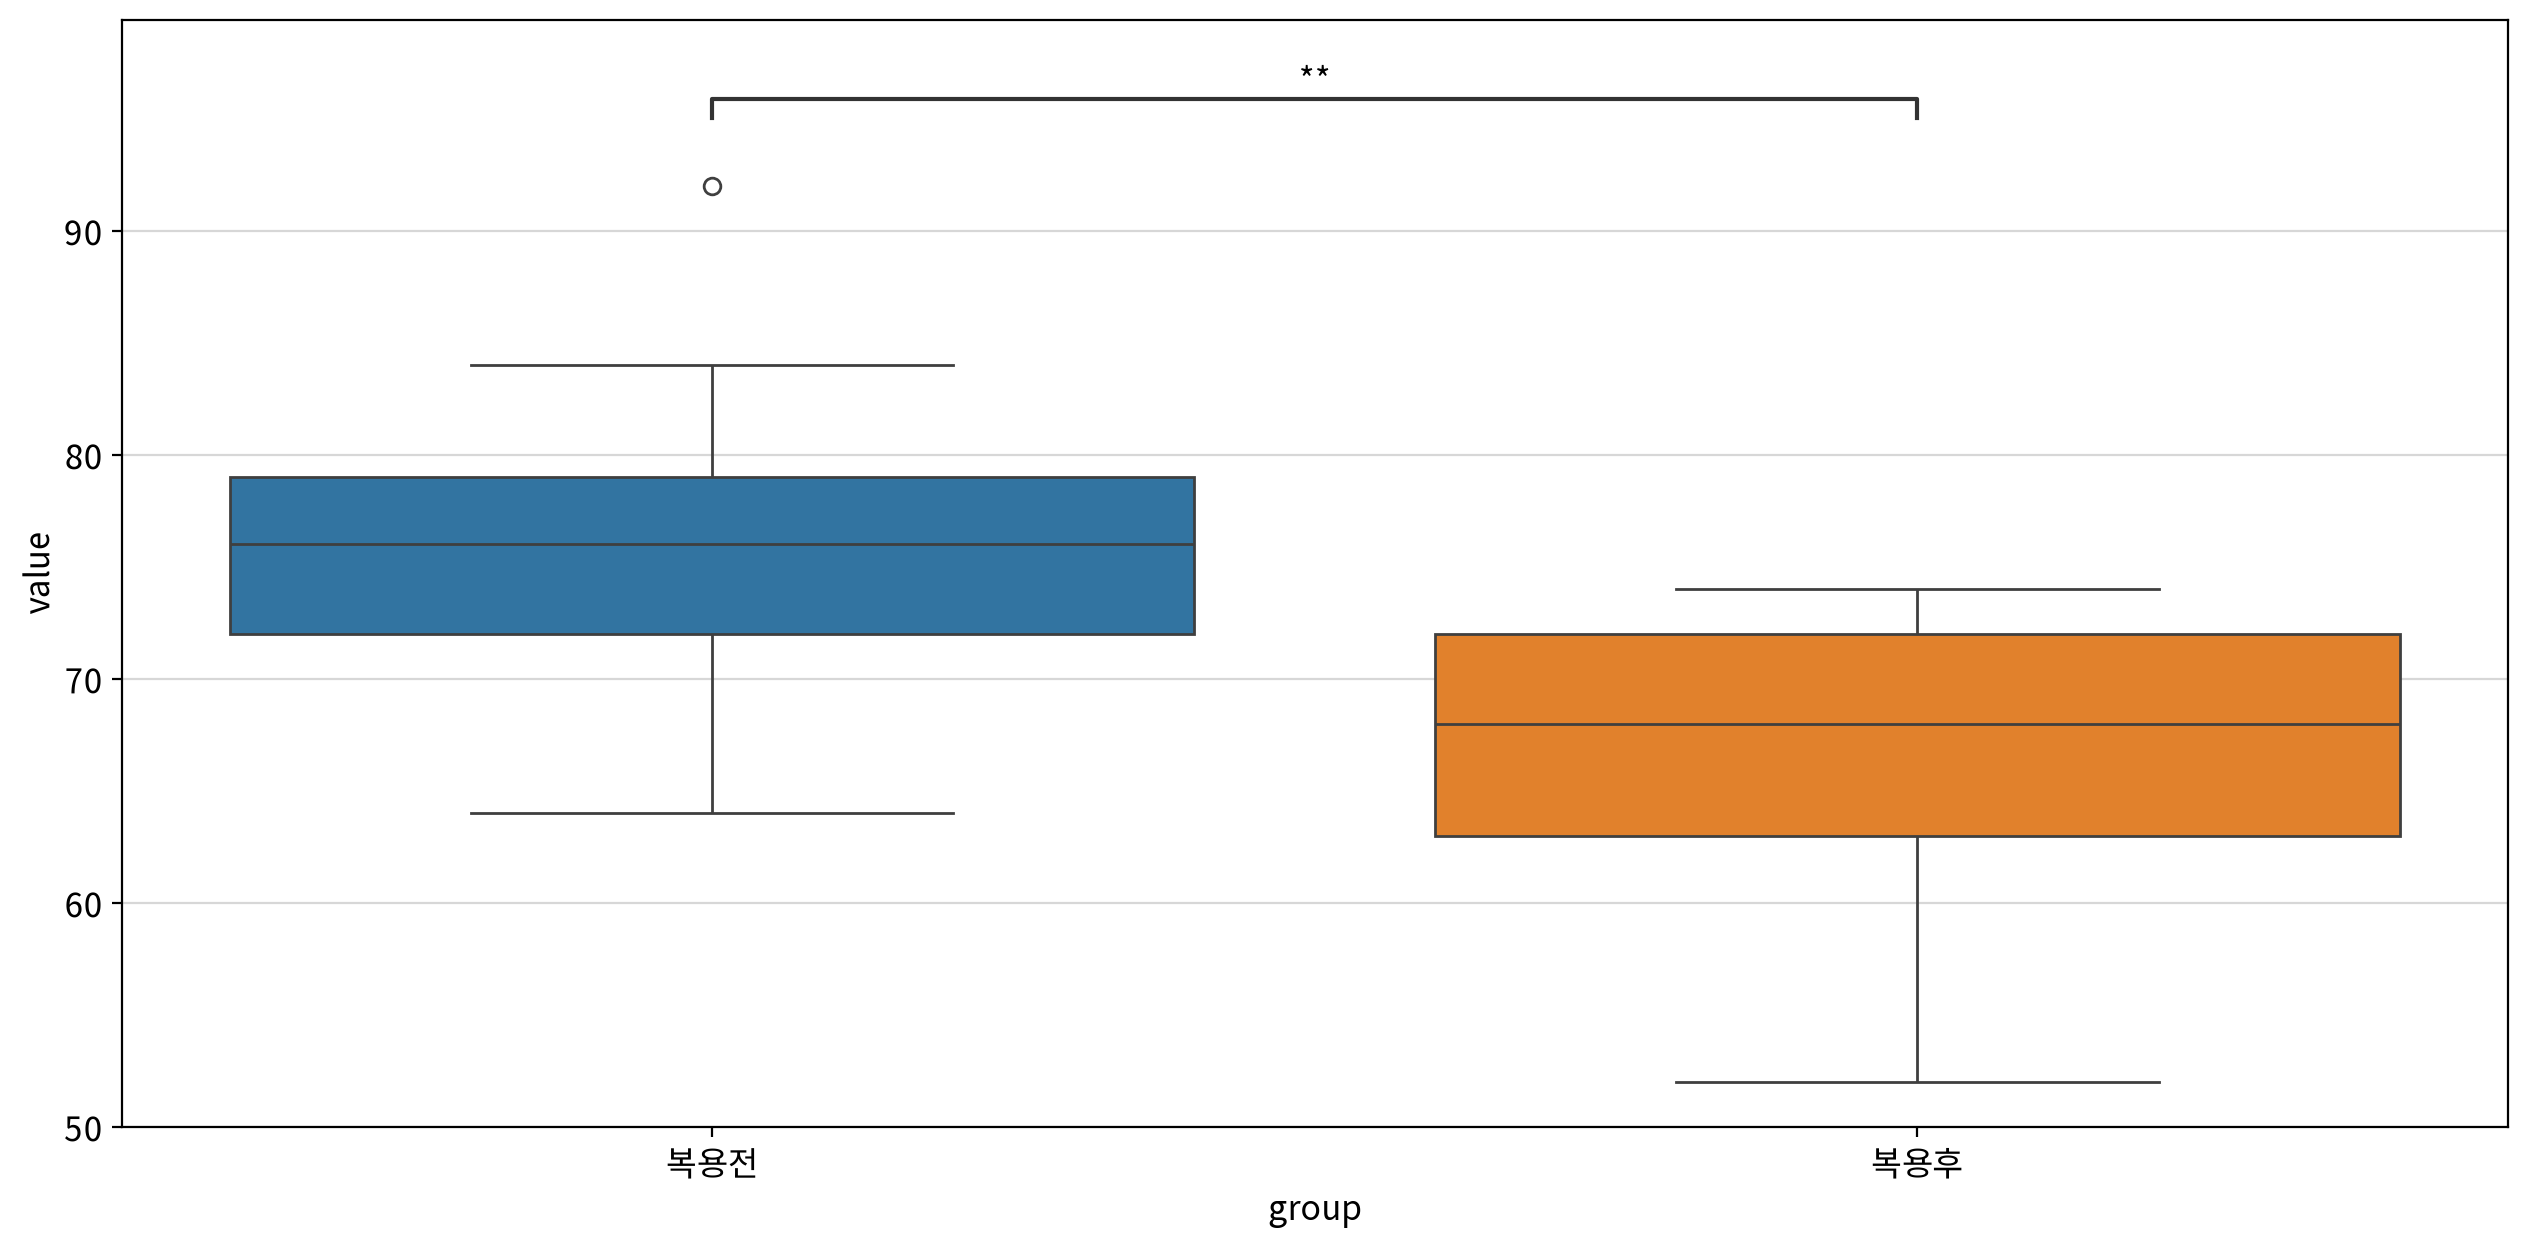

statistic  p-value  significant     result
test          alternative                                            
Paired t-test two-sided       -3.105    0.008         True  복용후 ≠ 복용전
              less            -3.105    0.004         True  복용후 < 복용전
              greater         -3.105    0.996        False  복용후 ≤ 복용전

In [24]:
my_stats.test_paired(data=df1, before='복용전', after='복용후')

차이값이 정규성을 충족하여 **대응표본 t-검정**을 수행하였다. 복용 전후 혈압의 차이는 통계적으로 유의하며(t = -3.105, 양측 p = 0.008 < 0.05), 단측 검정에서도 `복용후 < 복용전`이 유의하다(p = 0.004).

즉, 피임약 복용 후 혈압이 유의하게 **감소**하였으며, 피임약 복용은 혈압에 영향(혈압을 낮추는 방향)을 준다고 할 수 있다.

#### 문제2

`runner_diet` 데이터셋은 고등학교 육상선수 10명에게 감량훈련(2~4kg 정도)을 시킨 후 100m 달리기를 실시한 결과를 조사한 데이터이다.   
이들 중 체중과 육상선수에게 체중감량을 시키면 달리기에 어떤 변화가 일어나는지 조사하고자 한다.   
감량 전과 후에 달리기 속도에 차이가 있는지 분석하라.

In [25]:
# 데이터 불러오기
df2 = load_data("runner_diet")
df2.head()

📚 고등학교 육상선수 10명에게 감량훈련(2~4kg 정도)을 시킨 후 100m 달리기를 실시한 결과를 조사한 데이터 (출처: 방송통신대학교 통계학개론)


,감량전,감량후
0,14.500,14.300
1,13.400,13.400
2,13.000,13.100
3,14.500,13.900
4,13.300,13.100


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

감량전 vs. 감량후: t-test paired samples, P_val:4.155e-02 t=2.375e+00


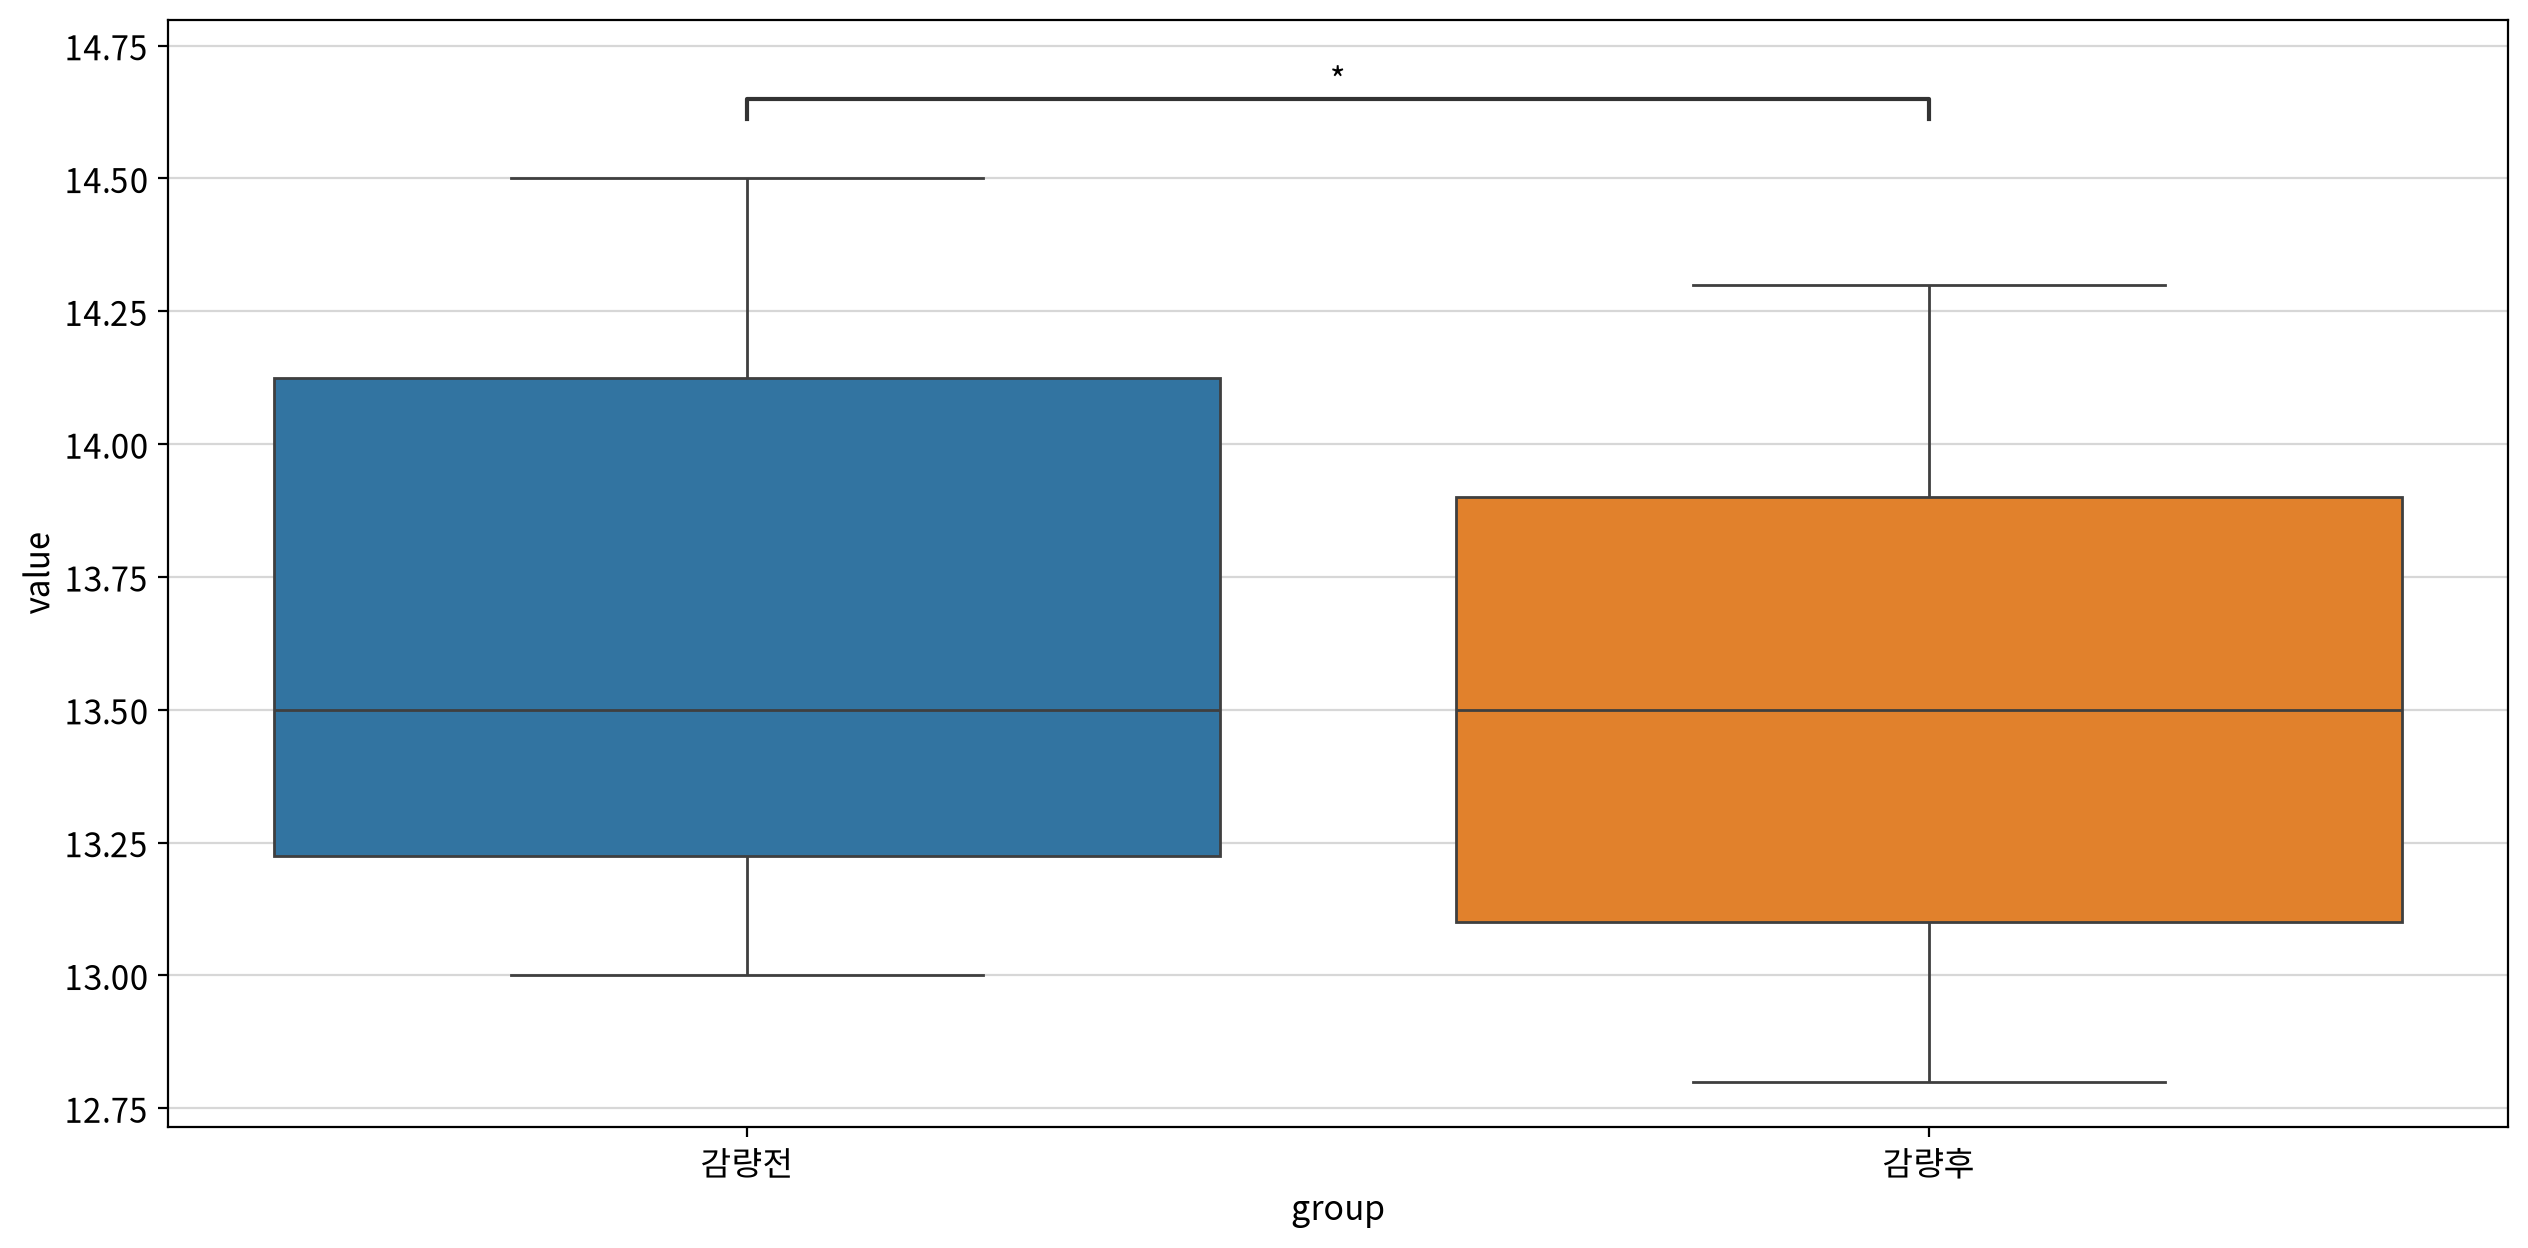

statistic  p-value  significant     result
test          alternative                                            
Paired t-test two-sided       -2.375    0.042         True  감량후 ≠ 감량전
              less            -2.375    0.021         True  감량후 < 감량전
              greater         -2.375    0.979        False  감량후 ≤ 감량전

In [26]:
my_stats.test_paired(data=df2, before='감량전', after='감량후')

차이값이 정규성을 충족하여 **대응표본 t-검정**을 수행하였다. 감량 전후 100m 기록의 차이는 통계적으로 유의하며(t = -2.375, 양측 p = 0.042 < 0.05), 단측 검정에서 `감량후 < 감량전`이 유의하다(p = 0.021).

즉, 체중감량 후 100m 기록이 유의하게 **단축**되었으며, 감량은 육상선수의 달리기 기록을 향상(속도 증가)시킨다고 할 수 있다.

#### 문제3

`wrestler_diet` 데이터셋은 고등학교 레슬링 선수에게 체중감량을 시키면 체력에 어떤 변화가 일어나는지 조사하기 위하여,   
어느 고등학교의 레슬링 선수 12명을 표본추출하여 감량시킨 후 얻은 데이터이다.   
감량 전과 감량 후 간에 차이가 있는가의 대응비교를 악력, 윗몸일으키기, 턱걸이에 대하여 실시하고 분석하라.

In [27]:
# 데이터 불러오기
df3 = load_data("wrestler_diet")
df3.head()

📚 고등학교 레슬링 선수에게 체중감량을 시키면 체력에 어떤 변화가 일어나는지 조사하기 위하여, 어느 고등학교의 레슬링 선수 12명을 표본추출하여 감량시킨 후 얻은 데이터 (출처: 방송통신대학교 통계학개론)


,이름,감량전 악력,감량후 악력,감량전 윗몸일으키기,감량후 윗몸일으키기,감량전 턱걸이,감량후 턱걸이
0,B.S,43,41,35,41,25,29
1,P.J,42,41,40,44,25,29
2,G.G,52,50,36,41,22,23
3,A.L,53,52,38,42,10,15
4,I.H,44,40,36,42,15,19


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

감량전 악력 vs. 감량후 악력: Wilcoxon test (paired samples), P_val:3.516e-02 Stat=9.000e+00


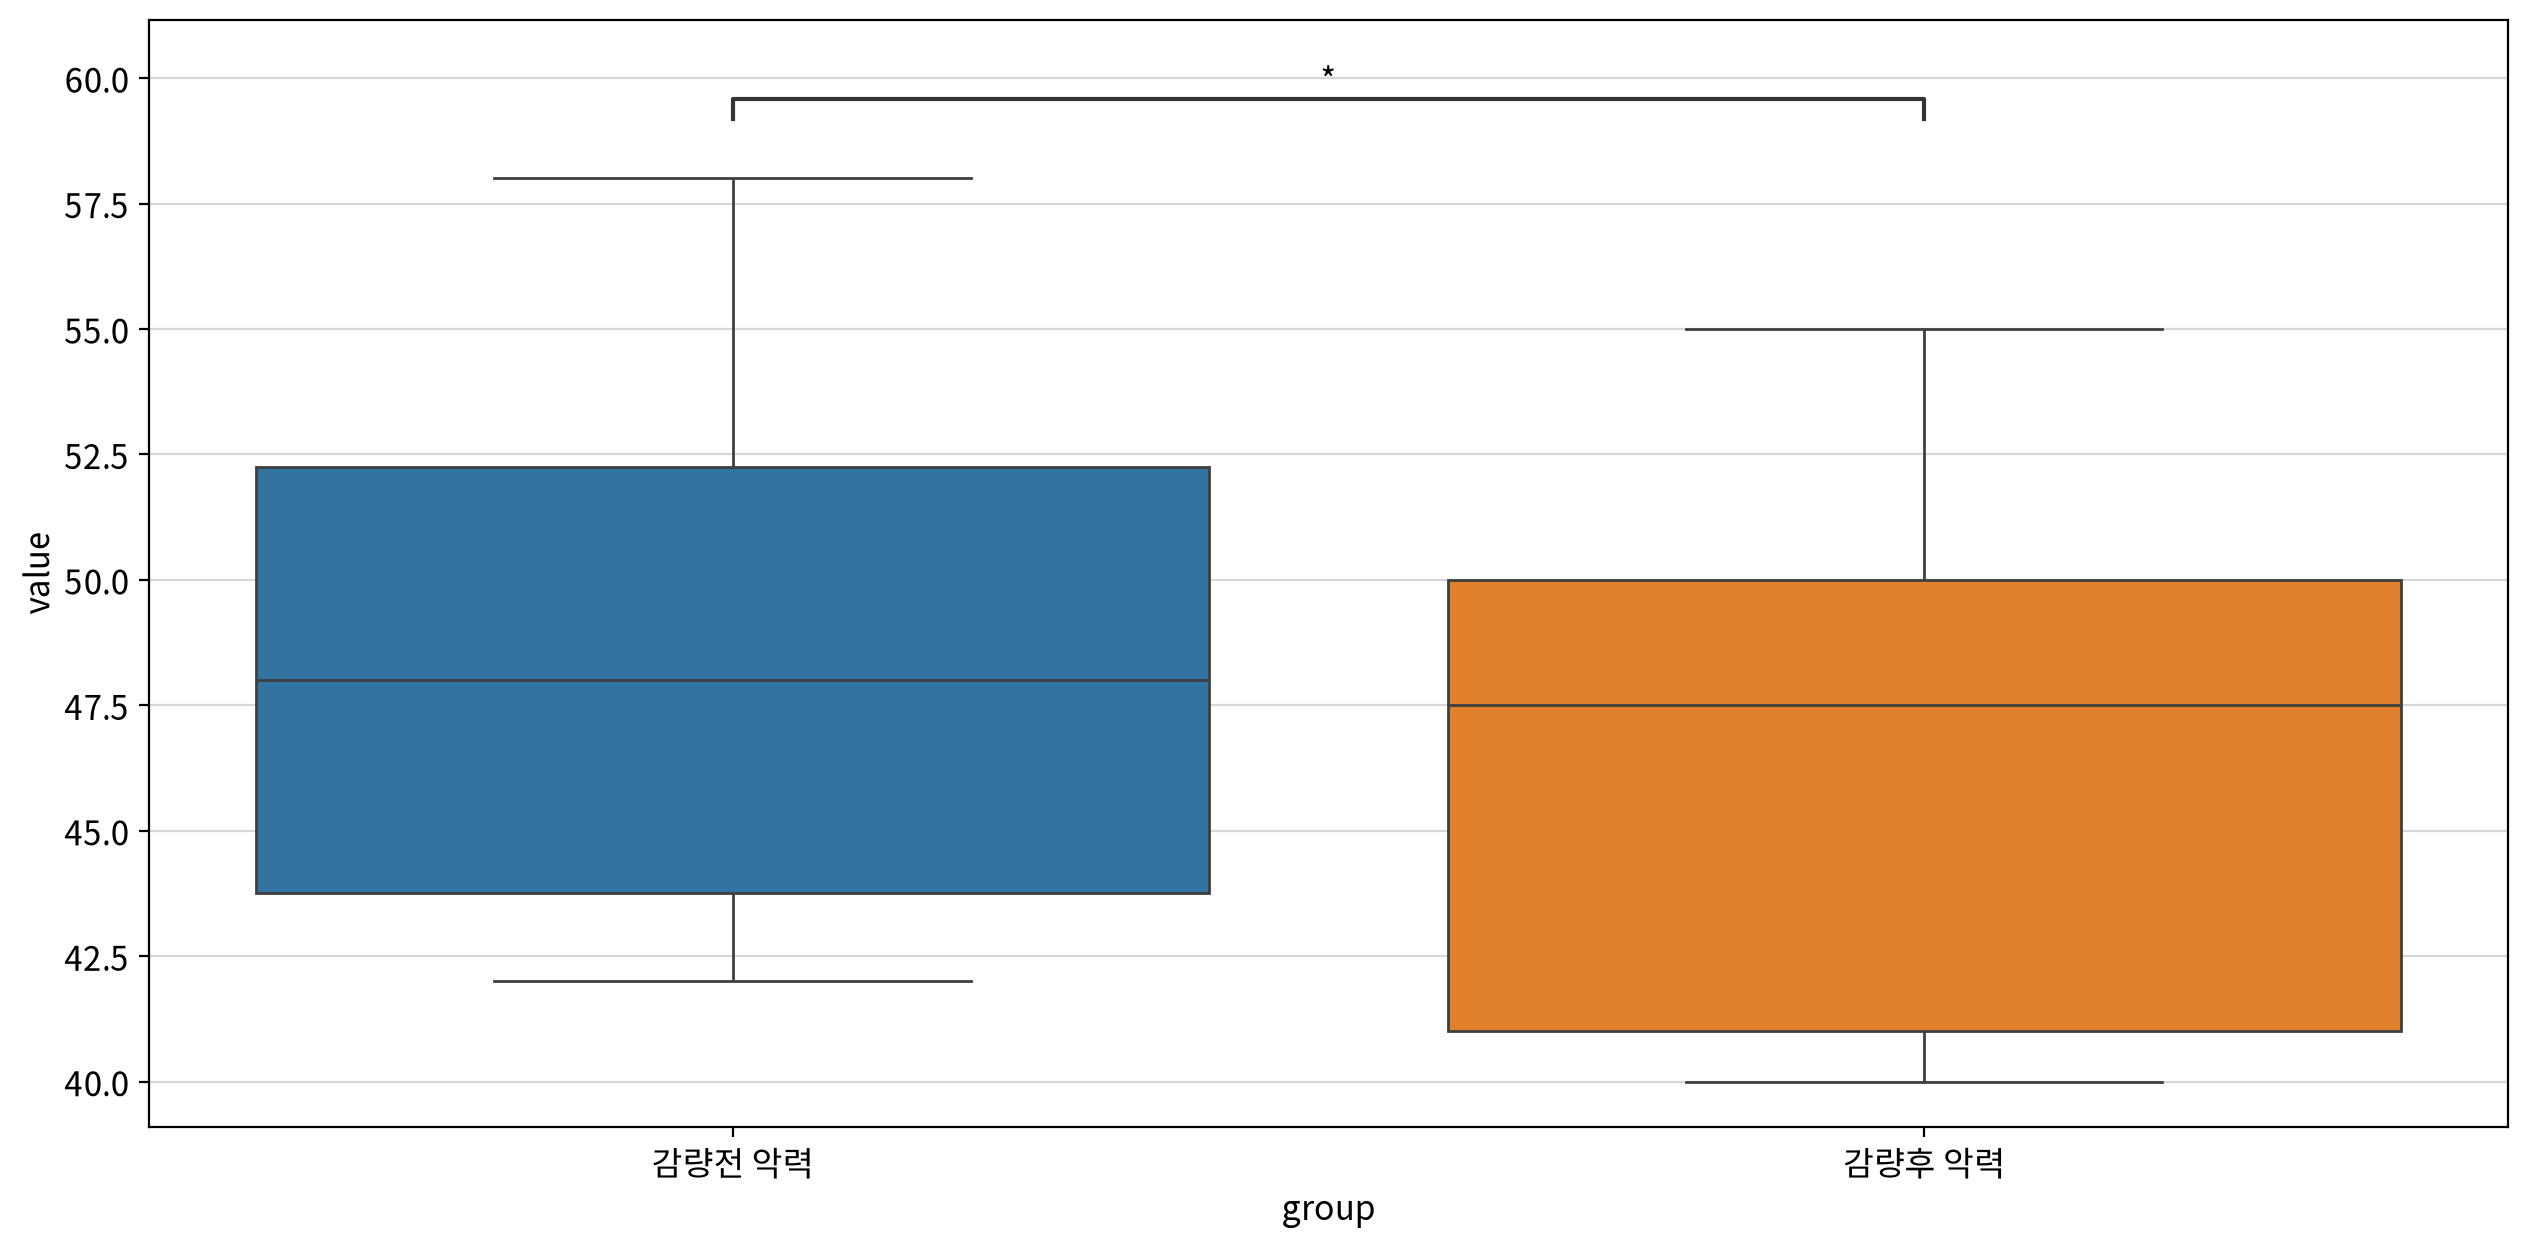

statistic  p-value  significant  \
test                      alternative                                    
Wilcoxon signed-rank test two-sided        9.000    0.035         True   
                          less             9.000    0.018         True   
                          greater          9.000    0.991        False   

                                                result  
test                      alternative                   
Wilcoxon signed-rank test two-sided    감량후 악력 ≠ 감량전 악력  
                          less         감량후 악력 < 감량전 악력  
                          greater      감량후 악력 ≤ 감량전 악력

In [28]:
my_stats.test_paired(data=df3, before='감량전 악력', after='감량후 악력')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

감량전 윗몸일으키기 vs. 감량후 윗몸일으키기: t-test paired samples, P_val:1.798e-05 t=-7.180e+00


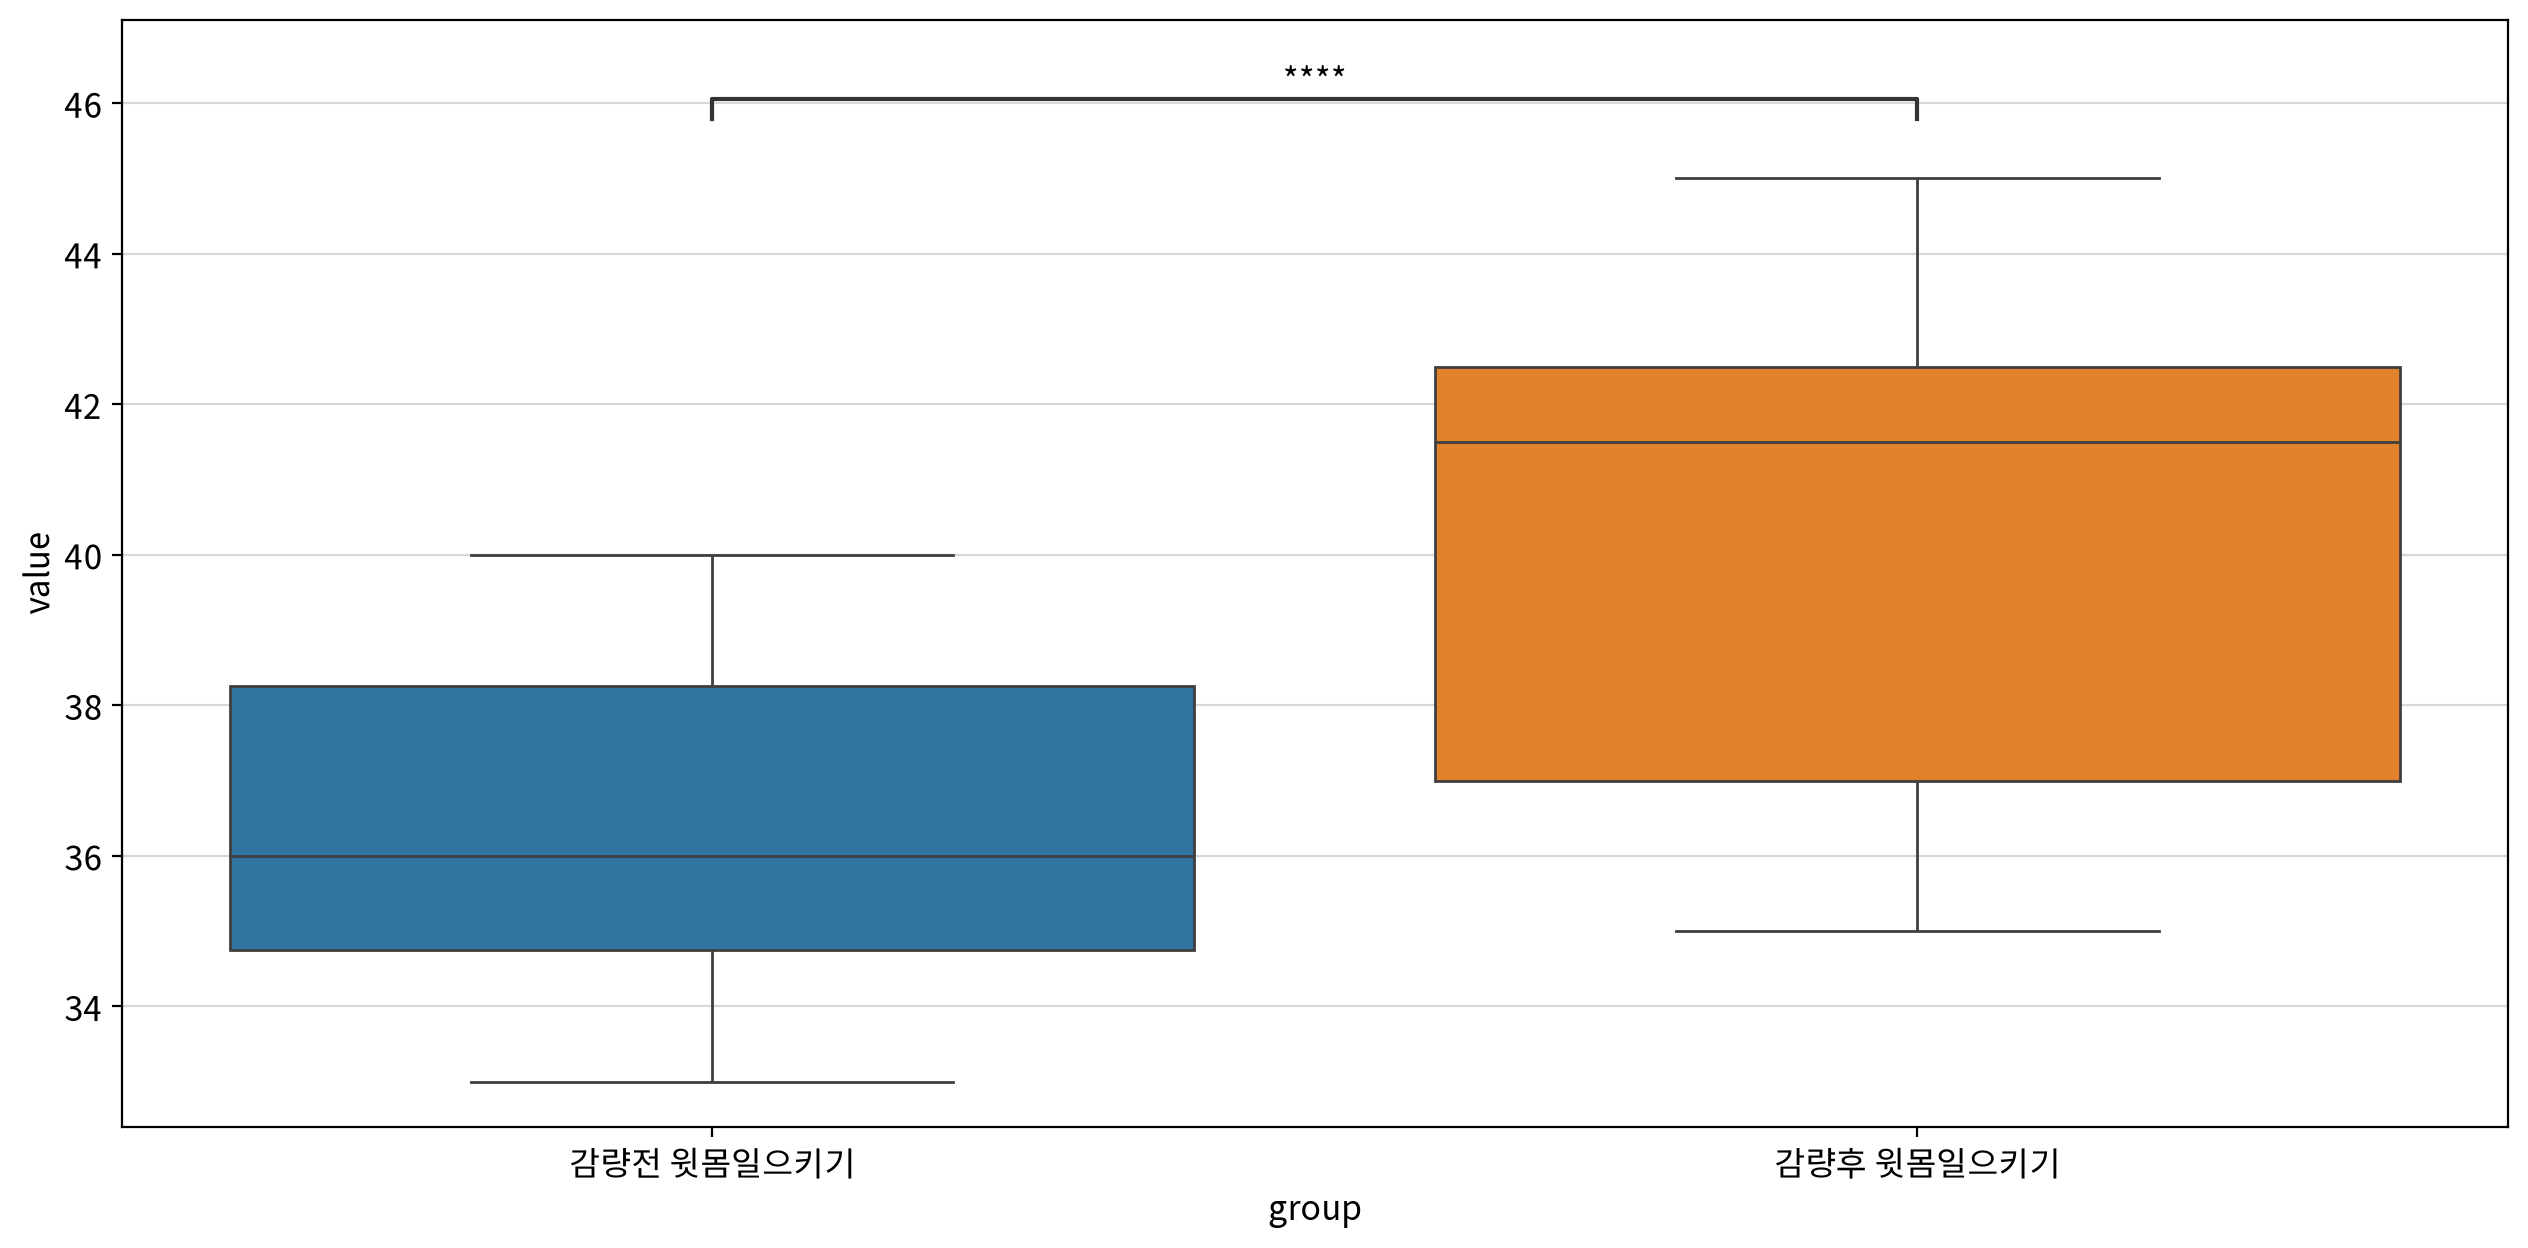

statistic  p-value  significant  \
test          alternative                                    
Paired t-test two-sided        7.180    0.000         True   
              less             7.180    1.000        False   
              greater          7.180    0.000         True   

                                            result  
test          alternative                           
Paired t-test two-sided    감량후 윗몸일으키기 ≠ 감량전 윗몸일으키기  
              less         감량후 윗몸일으키기 ≥ 감량전 윗몸일으키기  
              greater      감량후 윗몸일으키기 > 감량전 윗몸일으키기

In [29]:
my_stats.test_paired(data=df3, before='감량전 윗몸일으키기', after='감량후 윗몸일으키기')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

감량전 턱걸이 vs. 감량후 턱걸이: t-test paired samples, P_val:2.794e-05 t=-6.842e+00


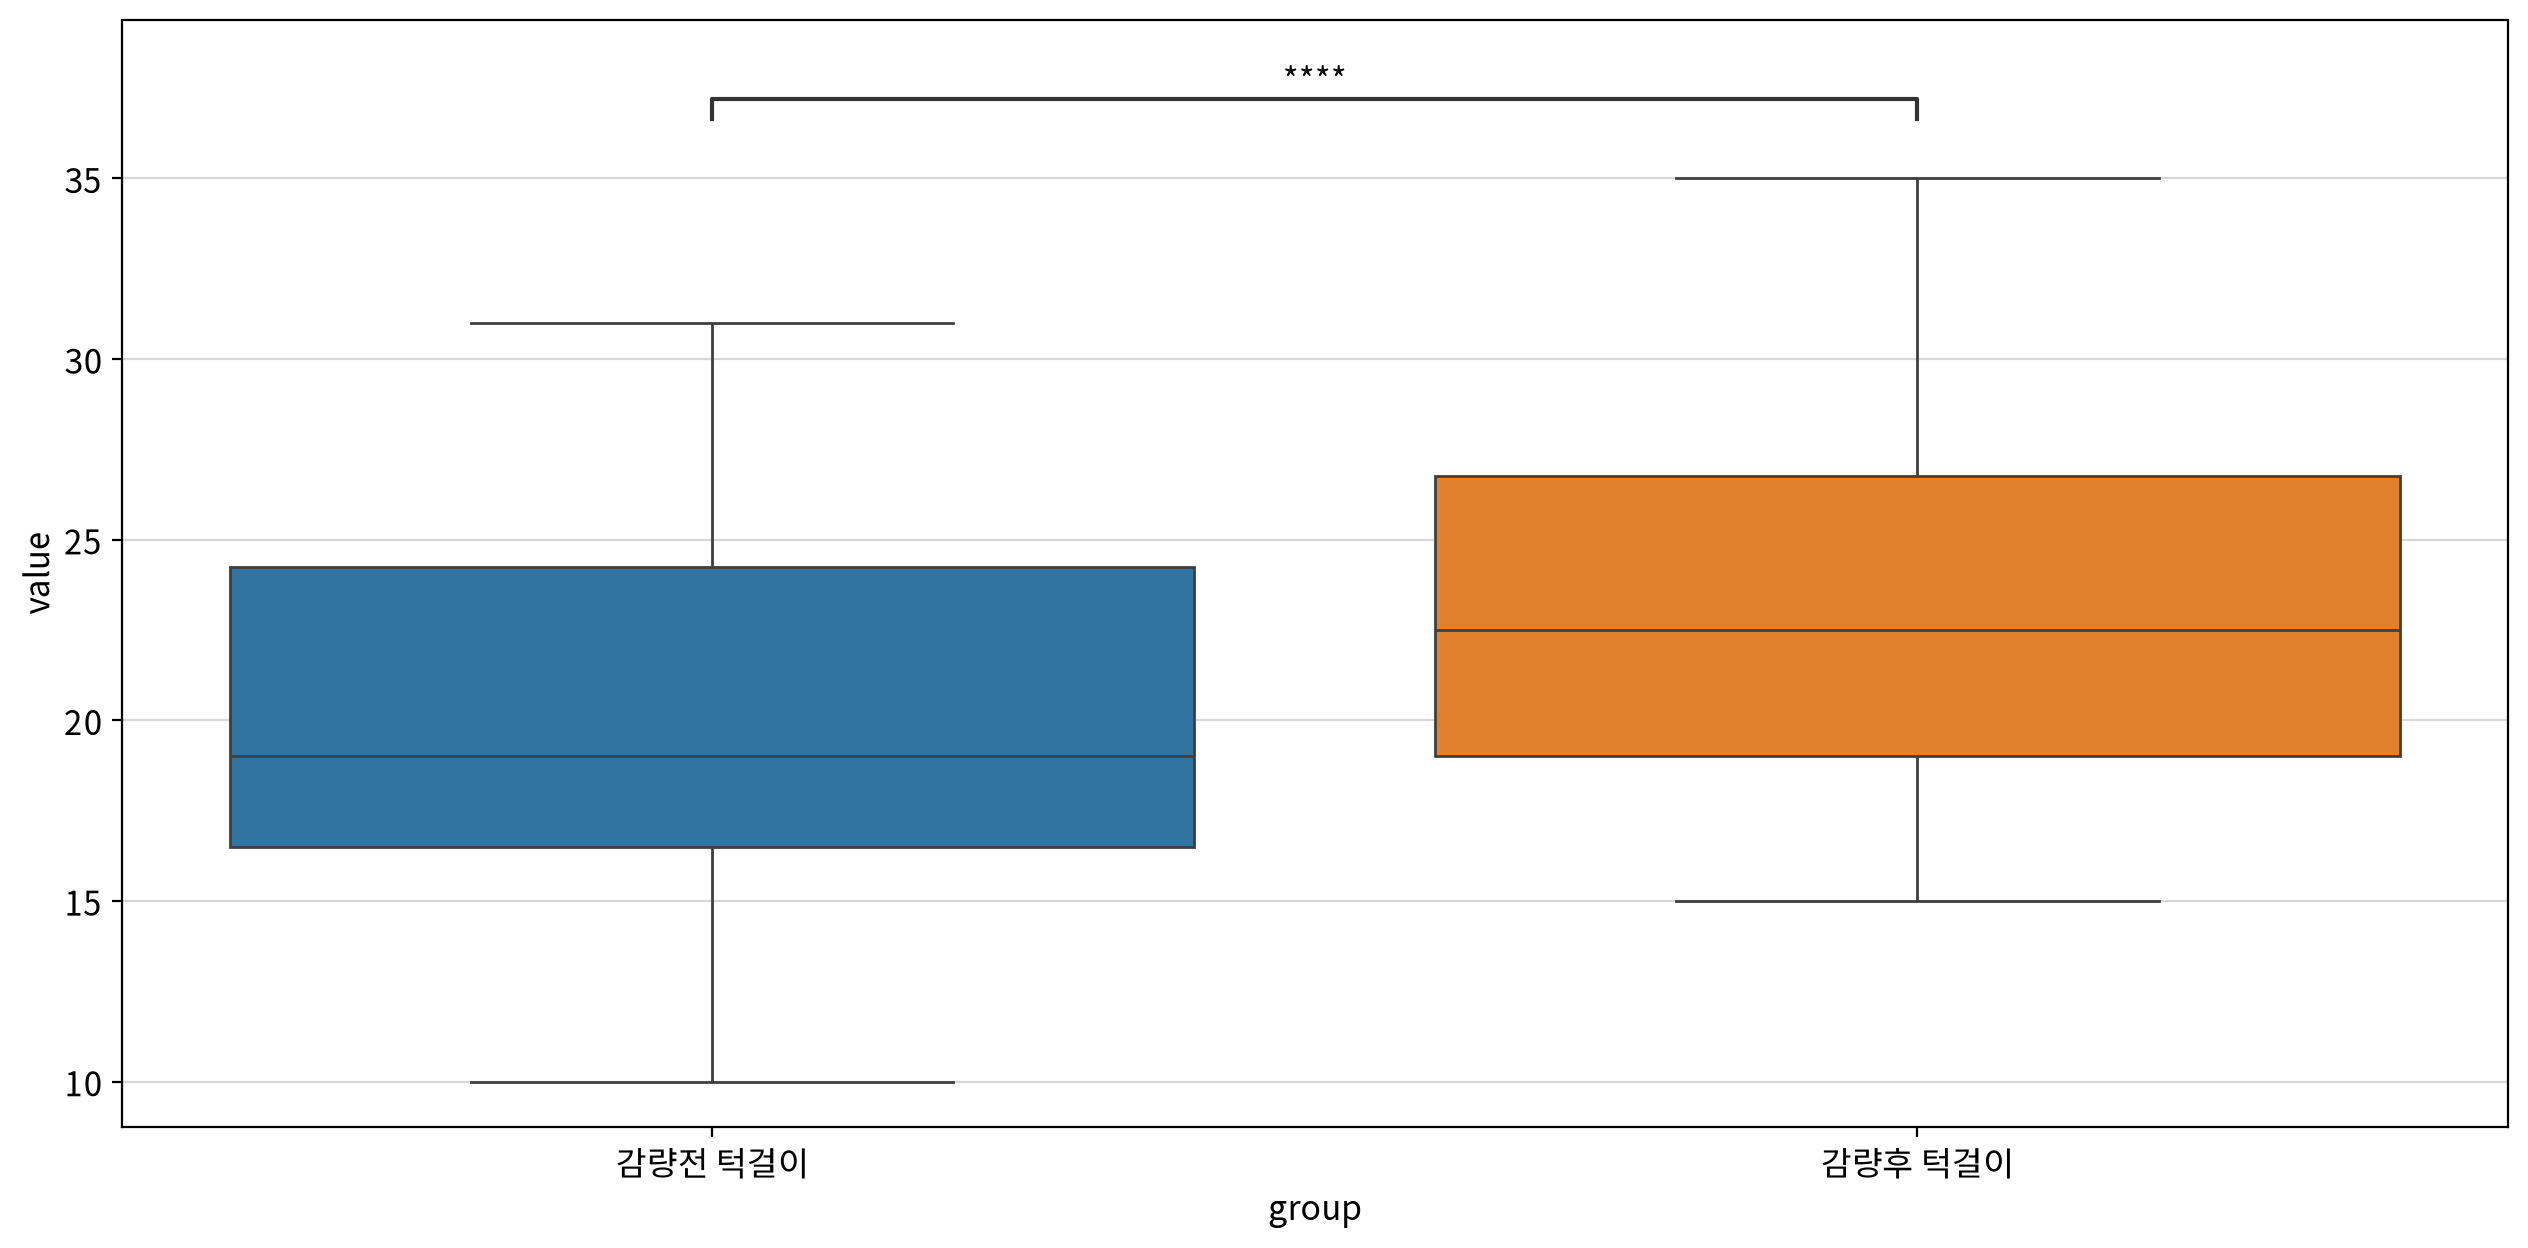

statistic  p-value  significant             result
test          alternative                                                    
Paired t-test two-sided        6.842    0.000         True  감량후 턱걸이 ≠ 감량전 턱걸이
              less             6.842    1.000        False  감량후 턱걸이 ≥ 감량전 턱걸이
              greater          6.842    0.000         True  감량후 턱걸이 > 감량전 턱걸이

In [30]:
my_stats.test_paired(data=df3, before='감량전 턱걸이', after='감량후 턱걸이')

악력·윗몸일으키기·턱걸이 세 항목 모두 감량 전후 차이가 통계적으로 유의하였다.

- **악력**: 정규성 미충족으로 Wilcoxon 검정 수행. 양측 p = 0.035 < 0.05로 유의하며 `감량후 < 감량전`(단측 p = 0.018) → 유의하게 **감소**.
- **윗몸일으키기**: 대응표본 t-검정. 양측 p < 0.001로 유의하며 `감량후 > 감량전`(단측 p < 0.001) → 유의하게 **증가**.
- **턱걸이**: 대응표본 t-검정. 양측 p < 0.001로 유의하며 `감량후 > 감량전`(단측 p < 0.001) → 유의하게 **증가**.

즉, 체중감량 후 악력(근력)은 감소한 반면, 윗몸일으키기·턱걸이(근지구력)는 향상되었다.

#### 문제4

서울시에서 정의하는 상권의 종류는 발달상권, 골목상권, 관광특구, 전통시장이 있다.   
`commercial` 데이터는 서울시의 2023년 상권에 따른 분기별 매출액과 매출건수에 대한 자료이다.   
주어진 데이터를 활용하여 서울시 골목상권의 2023년 상반기(1,2분기)와 하반기(3,4분기) 매출액이 어떤 차이를 보이는지 분석하라.   
주어진 데이터는 서울시에서 제공하는 집계가 완료된 데이터이므로 모든 결측치는 없는 상태이며   
이상치도 실제 매출 데이터이므로 별도의 정제 과정 없이 진행하는 것으로 한다.

In [31]:
# 라이브러리
import numpy as np
from pandas import pivot_table

# 데이터 불러오기
df4 = load_data("commercial")
df4.head()

📚 서울시의 2023년 상권에 따른 분기별 매출액과 매출건수에 대한 자료 (출처: 서울 열린데이터 광장)


,quarter,code,type,name,sales_amount,number_of_sales
0,1,3001491,관광특구,이태원 관광특구,-490799932,2496865
1,1,3001492,관광특구,명동 남대문 북창동 다동 무교동 관광특구,-135495143,10246122
2,1,3001493,관광특구,동대문패션타운 관광특구,92351597,2880324
3,1,3001494,관광특구,종로·청계 관광특구,1609259121,4960006
4,1,3001495,관광특구,잠실 관광특구,-589847108,5995166


In [32]:
# 골목상권 필터링 후 상반기/하반기로 나누기
df5 = df4.query("type == '골목상권'")
df5['half_year'] = np.where(df5['quarter'].isin([1, 2]), "상반기", "하반기")
df5

,quarter,code,type,name,sales_amount,number_of_sales,half_year
6,1,3110001,골목상권,이북5도청사,435264344,13080,상반기
7,1,3110002,골목상권,독립문역 1번,-232245647,339647,상반기
8,1,3110003,골목상권,세검정초등학교,576819152,16978,상반기
9,1,3110004,골목상권,대신고등학교,312840339,7706,상반기
10,1,3110005,골목상권,세검정,666679997,10162,상반기
...,...,...,...,...,...,...,...
5690,4,3111086,골목상권,한영중고,438057249,196999,하반기
5691,4,3111087,골목상권,고덕중학교(고덕2동주민센터),1644486933,65056,하반기
5692,4,3111088,골목상권,고덕동성당,-1341348758,158690,하반기
5693,4,3111089,골목상권,상일여고(상일초등학교),-171331589,430385,하반기


In [33]:
# 피벗 테이블
pivot1 = pivot_table(df5,
                     index= 'code',
                     columns= 'half_year',
                     values= 'sales_amount')
pivot1

half_year,상반기,하반기
code,,
3110001,579794482.500,660232165.500
3110002,-1118285029.000,-1364178977.000
3110003,816834877.500,971411239.000
3110004,378617224.500,398747715.000
3110005,738929894.500,808203808.500
...,...,...
3111086,-242395703.500,560936708.500
3111087,1315713158.000,1482799081.000
3111088,-1106300290.500,-1348983454.500


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

상반기 vs. 하반기: Wilcoxon test (paired samples), P_val:1.563e-17 Stat=1.802e+05


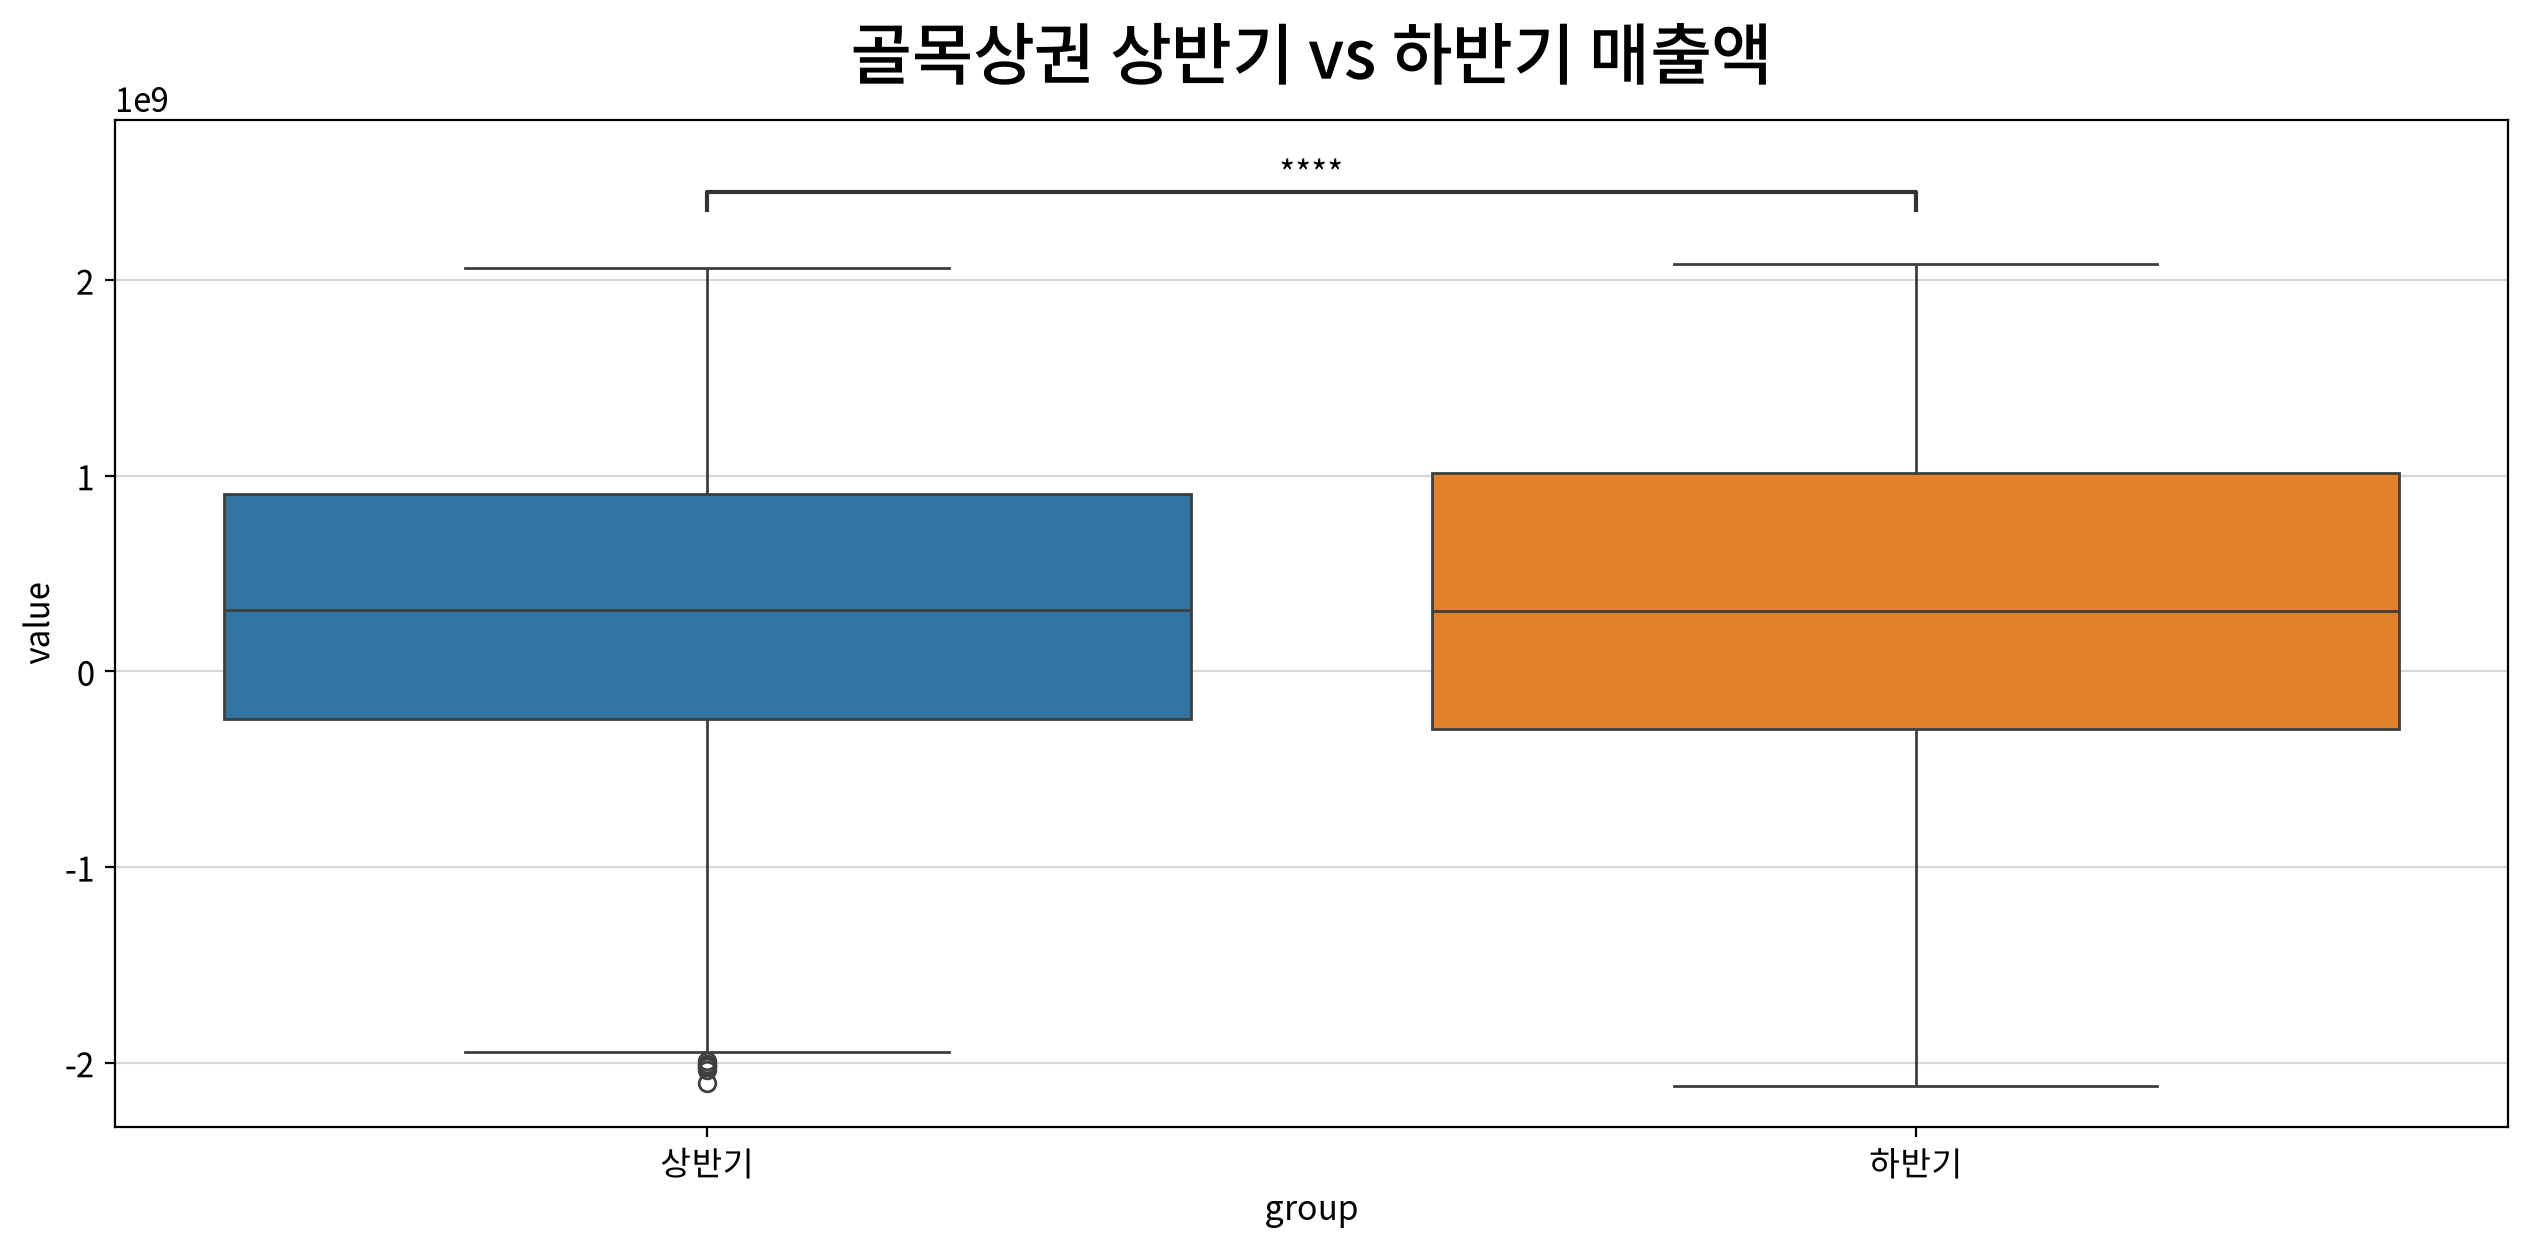

statistic  p-value  significant  \
test                      alternative                                    
Wilcoxon signed-rank test two-sided   180152.000    0.000         True   
                          less        340558.000    1.000        False   
                          greater     340558.000    0.000         True   

                                          result  
test                      alternative             
Wilcoxon signed-rank test two-sided    하반기 ≠ 상반기  
                          less         하반기 ≥ 상반기  
                          greater      하반기 > 상반기

In [35]:
my_stats.test_paired(pivot1, '상반기', '하반기', title='골목상권 상반기 vs 하반기 매출액')

상·하반기 매출액의 차이값이 정규성을 충족하지 않아 **Wilcoxon 부호순위 검정**을 수행하였다. 골목상권의 상·하반기 매출액 차이는 통계적으로 매우 유의하며(양측 p ≈ 1.6e-94 < 0.05), 단측 검정에서 `하반기 > 상반기`가 유의하다(p < 0.001).

즉, 서울시 골목상권의 2023년 하반기 매출액은 상반기보다 유의하게 **높다**.